In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.load_dataset import laod_dataframes

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from surprise import SVD, Dataset, Reader

1. Загрузка данных

In [2]:
dataset_dict = laod_dataframes()

df_books = dataset_dict["df_books"]
df_ratings = dataset_dict["df_ratings"]
df_book_tags = dataset_dict["df_book_tags"]
df_tags = dataset_dict["df_tags"]
df_to_read = dataset_dict["df_to_read"]

In [3]:
for name, df in dataset_dict.items():
    print(f"{name}: {df.shape}")
    print(df.columns.tolist())
    print("-" * 50)

df_books: (10000, 23)
['id', 'book_id', 'best_book_id', 'work_id', 'books_count', 'isbn', 'isbn13', 'authors', 'original_publication_year', 'original_title', 'title', 'language_code', 'average_rating', 'ratings_count', 'work_ratings_count', 'work_text_reviews_count', 'ratings_1', 'ratings_2', 'ratings_3', 'ratings_4', 'ratings_5', 'image_url', 'small_image_url']
--------------------------------------------------
df_ratings: (981756, 3)
['book_id', 'user_id', 'rating']
--------------------------------------------------
df_book_tags: (999912, 3)
['goodreads_book_id', 'tag_id', 'count']
--------------------------------------------------
df_tags: (34252, 2)
['tag_id', 'tag_name']
--------------------------------------------------
df_to_read: (912705, 2)
['user_id', 'book_id']
--------------------------------------------------


1.2 Очистка данных

In [4]:
def clean_ratings(df_ratings, df_books):
    """Отчистка рейтингов"""
    ratings = df_ratings[["user_id", "book_id", "rating"]].copy()

    ratings = ratings.dropna()
    ratings = ratings.groupby(['user_id','book_id' ], as_index=False)['rating'].agg('mean')
    # Оставляем книги, которые присутствуют в каталоге
    ratings = ratings[ratings["book_id"].isin(df_books["id"])]

    return ratings.reset_index(drop=True)


ratings = clean_ratings(df_ratings, df_books)
print("Количество взаимодействий:", len(ratings))
print("Пользователей:", ratings["user_id"].nunique())
print("Книг:", ratings["book_id"].nunique())

Количество взаимодействий: 979478
Пользователей: 53424
Книг: 10000


1.3. Разделение на train, val и test

In [5]:
import numpy as np

def train_test_val_per_user(df, train_size=0.6, val_size=0.2, test_size=0.2,
                            min_ratings=3, random_state=42):
    """
    Сплит, при котором КАЖДЫЙ пользователь присутствует во всех трёх выборках.
    У каждого пользователя оставляем минимум 1 оценку в train.
    Пользователи с < min_ratings оценками — целиком в train.
    """
    assert abs(train_size + val_size + test_size - 1.0) < 1e-9

    rng = np.random.default_rng(random_state)
    df = df.copy()

    # случайный порядок внутри пользователя
    df["_rand"] = rng.random(len(df))
    df = df.sort_values(["user_id", "_rand"]).reset_index(drop=True)

    df["_rank"] = df.groupby("user_id").cumcount()
    n_per_user = df.groupby("user_id")["_rank"].transform("max") + 1  # Series

    # --- Считаем размеры val/test в numpy, чтобы не ловить pandas-ловушки ---
    n_per_user_np = n_per_user.to_numpy()
    too_few = n_per_user_np < min_ratings

    n_val  = np.maximum(np.floor(n_per_user_np * val_size).astype(int),  1)
    n_test = np.maximum(np.floor(n_per_user_np * test_size).astype(int), 1)

    # если у пользователя слишком мало оценок, чтобы дать всем по 1,
    # уменьшаем val/test, чтобы train остался >= 1
    # (страхуемся на случай min_ratings=3 и n=3: 1/1/1 — ок;
    #  но если n=2 и min_ratings=2 — тоже надо не уйти в 0)
    n_val  = np.where(n_per_user_np - n_val - n_test < 1,
                      np.maximum(n_per_user_np - n_test - 1, 0),
                      n_val)
    n_test = np.where(n_per_user_np - n_val - n_test < 1,
                      np.maximum(n_per_user_np - n_val - 1, 0),
                      n_test)
    n_train = n_per_user_np - n_val - n_test

    # пользователей с < min_ratings целиком в train
    n_train = np.where(too_few, n_per_user_np, n_train)
    n_val   = np.where(too_few, 0, n_val)
    n_test  = np.where(too_few, 0, n_test)

    # ---- привязываем размеры обратно к строкам ----
    # n_per_user — Series с индексом df.index, поэтому map по индексу безопасен
    idx = df.index
    user_vals = df["user_id"].to_numpy()

    # словарь user_id → (n_train, n_val)
    # (проще и надёжнее, чем transform по двум разным колонкам)
    sizes = {}
    seen = {}
    for uid, nt, nv in zip(user_vals, n_train, n_val):
        if uid not in seen:
            seen[uid] = True
            sizes[uid] = (nt, nv)

    df["_n_train"] = df["user_id"].map(lambda u: sizes[u][0])
    df["_n_val"]   = df["user_id"].map(lambda u: sizes[u][1])

    is_train = df["_rank"] < df["_n_train"]
    is_val   = (df["_rank"] >= df["_n_train"]) & (df["_rank"] < df["_n_train"] + df["_n_val"])
    is_test  = ~(is_train | is_val)

    cols_drop = ["_rand", "_rank", "_n_train", "_n_val"]
    train_df = df[is_train].drop(columns=cols_drop).reset_index(drop=True)
    val_df   = df[is_val].drop(columns=cols_drop).reset_index(drop=True)
    test_df  = df[is_test].drop(columns=cols_drop).reset_index(drop=True)

    return train_df, val_df, test_df


train_df, val_df, test_df = train_test_val_per_user(ratings, 0.6, 0.2, 0.2)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:<6}: {len(d):>8} | users: {d['user_id'].nunique():>6} | books: {d['book_id'].nunique()}")

print("\nusers in train ∩ val :", len(set(train_df['user_id']) & set(val_df['user_id'])))
print("users in train ∩ test:", len(set(train_df['user_id']) & set(test_df['user_id'])))
print("users in val   ∩ test:", len(set(val_df['user_id']) & set(test_df['user_id'])))

train :   614150 | users:  53424 | books: 10000
val   :   182664 | users:  45071 | books: 10000
test  :   182664 | users:  45071 | books: 10000

users in train ∩ val : 45071
users in train ∩ test: 45071
users in val   ∩ test: 45071


1.4 Создаем признаки user_history test_relevant val_relevant

In [6]:
user_history = (
    train_df.groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

# Только оценки 4 и 5 считаем релевантными
test_relevant = (
    test_df[test_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

# Только оценки 4 и 5 считаем релевантными
val_relevant = (
    val_df[val_df["rating"] >= 4]
    .groupby("user_id")["book_id"]
    .agg(set)
    .to_dict()
)

print("Пользователей с релевантными книгами test:",len(test_relevant))
print("Пользователей с релевантными книгами val:",len(val_relevant))

Пользователей с релевантными книгами test: 36910
Пользователей с релевантными книгами val: 36825


### 1.4.1 Расширенные признаки пользователей, книг и взаимодействий

- **Пользователь:** число оценок, средняя оценка, стандартное отклонение, доля оценок ≥ 4,
  логарифм активности, группа `new/regular/active`, разнообразие жанров и доли каждого жанра
  в положительной истории.
- **Книга:** популярность, средняя и сглаженная оценка, стандартное отклонение,
  число разных оценок и нормированная энтропия их распределения, жанры и основной жанр.
- **Пара пользователь–книга:** косинусное сходство с жанровым профилем, жанровая
  и авторская близость к положительной истории, разница средних оценок книги и пользователя.

Статистики оценок и история обучаются **только на train**. Для строк train используем
**leave-one-out**: исключаем собственное взаимодействие из всех обучающих статистик,
включая глобальное среднее, жанровый профиль и историю автора. Validation и test
получают признаки из полной истории train; их `rating` остаётся только целевой переменной.

Жанры — воспроизводимое приближение по словарю тематических тегов, допускающее несколько
жанров у книги. Названия, авторы и агрегированные теги считаем общедоступными метаданными
каталога; `books.average_rating` и внешние счётчики оценок в признаки не включаем.
`ratings.book_id` связывается с `books.id`, а теги — с Goodreads ID `books.book_id`.
Временных меток нет, поэтому активность описывает объём истории, а не частоту чтения во времени.

Разброс оценок рассчитан как стандартное отклонение генеральной совокупности (`ddof=0`).
Для энтропии и числа разных оценок средние дробные рейтинги округляются до категорий 1–5;
энтропия нормирована на `log(5)` и лежит в диапазоне [0, 1].


In [7]:
"""Расширенные признаки; этот код будет встроен в prototype.ipynb."""

GENRE_TAGS = {
    "fantasy": {"fantasy", "high-fantasy", "epic-fantasy", "urban-fantasy"},
    "science_fiction": {
        "science-fiction",
        "sci-fi",
        "scifi",
        "science-fiction-fantasy",
    },
    "romance": {"romance", "contemporary-romance", "historical-romance"},
    "mystery": {"mystery", "mysteries", "crime", "detective"},
    "thriller": {"thriller", "thrillers", "suspense"},
    "horror": {"horror", "paranormal"},
    "historical": {"historical-fiction", "historical", "history"},
    "young_adult": {"young-adult", "ya", "teen", "teen-fiction"},
    "children": {"children", "childrens", "children-s", "middle-grade"},
    "classics": {"classics", "classic", "literary-fiction"},
    "nonfiction": {"non-fiction", "nonfiction", "essays"},
    "biography": {"biography", "biographies", "memoir", "memoirs", "autobiography"},
    "poetry": {"poetry", "poems"},
    "comics": {"comics", "graphic-novels", "graphic-novel", "manga"},
}


class ExtendedFeatureBuilder:
    """Обучающие статистики отделены от преобразования пар (user_id, book_id)."""

    @staticmethod
    def _stats(frame, key, prefix):
        data = frame.assign(
            _square=frame["rating"] ** 2, _positive=frame["rating"] >= 4
        )
        stats = data.groupby(key).agg(
            count=("rating", "size"),
            total=("rating", "sum"),
            square=("_square", "sum"),
            positive=("_positive", "sum"),
        )
        return stats.add_prefix(prefix + "_")

    def fit(self, train, books, book_tags, tags):
        required = train[["user_id", "book_id", "rating"]].copy()
        if required.empty or required.isna().any().any():
            raise ValueError("Нужен непустой train без пропусков")
        if required.duplicated(["user_id", "book_id"]).any():
            raise ValueError("Сначала агрегируйте повторные пары user_id/book_id")
        if not required["book_id"].isin(books["id"]).all():
            raise ValueError("Книги train должны присутствовать в каталоге books.id")
        self.train = required
        self.train_index = required.set_index(["user_id", "book_id"])
        self.global_mean = float(required["rating"].mean())
        self.global_sum = float(required["rating"].sum())
        self.user_stats = self._stats(required, "user_id", "user")
        self.book_stats = self._stats(required, "book_id", "book")
        self.genres = list(GENRE_TAGS)
        catalog = books[["id", "book_id", "title", "authors"]].copy()
        if catalog["id"].duplicated().any():
            raise ValueError("books.id должен быть уникальным")

        # В ratings.book_id хранится books.id; books.book_id — Goodreads ID для тегов.
        tag_to_genre = {
            tag: genre for genre, names in GENRE_TAGS.items() for tag in names
        }
        tagged = book_tags.merge(tags[["tag_id", "tag_name"]], on="tag_id", how="left")
        tagged["genre"] = tagged["tag_name"].str.lower().str.strip().map(tag_to_genre)
        genre_counts = (
            tagged.dropna(subset=["genre"])
            .pivot_table(
                index="goodreads_book_id",
                columns="genre",
                values="count",
                aggfunc="sum",
                fill_value=0,
            )
            .reindex(columns=self.genres, fill_value=0)
        )
        counts = genre_counts.reindex(catalog["book_id"], fill_value=0)
        counts.index = catalog["id"].to_numpy()
        self.genre_matrix = (counts > 0).astype(np.float32)
        self.genre_matrix.index.name = "book_id"
        catalog["main_genre"] = np.where(
            counts.sum(axis=1).to_numpy() > 0,
            counts.idxmax(axis=1).to_numpy(),
            "unknown",
        )
        catalog["primary_author"] = (
            catalog["authors"].fillna("").str.split(",").str[0].str.strip()
        )
        self.catalog = (
            catalog.drop(columns=["book_id"])
            .rename(columns={"id": "book_id"})
            .set_index("book_id")
        )

        buckets = required["rating"].round().clip(1, 5).astype(int)
        self.rating_histogram = pd.crosstab(required["book_id"], buckets).reindex(
            columns=range(1, 6), fill_value=0
        )
        positive = required[required["rating"] >= 4]
        positive_genres = self.genre_matrix.reindex(positive["book_id"]).to_numpy()
        self.user_genres = (
            pd.DataFrame(positive_genres, columns=self.genres)
            .groupby(positive["user_id"].to_numpy())
            .sum()
        )
        authors = positive.merge(
            self.catalog[["primary_author"]], on="book_id", how="left"
        )
        self.user_authors = (
            authors[authors["primary_author"] != ""]
            .groupby(["user_id", "primary_author"])
            .size()
        )
        return self

    def transform(self, pairs, leave_one_out=False):
        """rating сохраняется как target и не читается при вычислении признаков.

        leave_one_out=True применяется только к парам train: собственный рейтинг
        исключается из статистик пользователя, книги, автора и жанрового профиля.
        """
        result = pairs.reset_index(drop=True).copy()
        users, books = result["user_id"], result["book_id"]
        if not books.isin(self.catalog.index).all():
            raise ValueError("Для признаков книги нужен её каталог")
        keys = pd.MultiIndex.from_frame(result[["user_id", "book_id"]])
        removed = np.zeros(len(result))
        if leave_one_out:
            source = self.train_index.reindex(keys)["rating"]
            if source.isna().any():
                raise ValueError("leave_one_out допустим только для пар train")
            removed = source.to_numpy()
        subtract = int(leave_one_out)
        positive_removed = (removed >= 4).astype(int)
        prior = np.full(len(result), self.global_mean)
        if leave_one_out:
            prior = (
                (self.global_sum - removed) / (len(self.train) - 1)
                if len(self.train) > 1
                else np.full(len(result), 3.0)
            )

        for prefix, identifiers, stats in [
            ("user", users, self.user_stats),
            ("book", books, self.book_stats),
        ]:
            values = stats.reindex(identifiers).fillna(0)
            n = values[f"{prefix}_count"].to_numpy() - subtract
            total = values[f"{prefix}_total"].to_numpy() - removed
            squares = values[f"{prefix}_square"].to_numpy() - removed**2
            positives = values[f"{prefix}_positive"].to_numpy() - positive_removed
            mean = np.divide(total, n, out=prior.copy(), where=n > 0)
            variance = np.divide(
                squares, n, out=np.zeros(len(result)), where=n > 0
            ) - np.where(n > 0, mean**2, 0)
            result[f"{prefix}_ratings_count"] = n.astype(int)
            result[f"{prefix}_mean_rating"] = mean
            result[f"{prefix}_rating_std"] = np.sqrt(np.maximum(variance, 0))
            result[f"{prefix}_positive_share"] = np.divide(
                positives, n, out=np.zeros(len(result)), where=n > 0
            )
            result[f"{prefix}_log_activity"] = np.log1p(n)
            if prefix == "user":
                user_positive_count = positives

        result["user_activity_group"] = pd.cut(
            result["user_ratings_count"],
            bins=[-1, 4, 49, np.inf],
            labels=["new", "regular", "active"],
        ).astype(str)
        result["book_popularity_share"] = result["book_ratings_count"] / max(
            len(self.train) - subtract, 1
        )
        result["book_smoothed_rating"] = (
            result["book_mean_rating"] * result["book_ratings_count"] + 50 * prior
        ) / (result["book_ratings_count"] + 50)
        histogram = self.rating_histogram.reindex(books).fillna(0).to_numpy(dtype=float, copy=True)
        if leave_one_out:
            histogram[
                np.arange(len(result)), np.rint(removed).clip(1, 5).astype(int) - 1
            ] -= 1
        n_book = result["book_ratings_count"].to_numpy()[:, None]
        probabilities = np.divide(
            histogram, n_book, out=np.zeros_like(histogram), where=n_book > 0
        )
        result["book_rating_entropy"] = -(
            probabilities * np.log(np.maximum(probabilities, 1e-12))
        ).sum(axis=1) / np.log(5)
        result["book_distinct_ratings"] = (histogram > 0).sum(axis=1)

        genre_vectors = self.genre_matrix.reindex(books).to_numpy()
        profiles = self.user_genres.reindex(users).fillna(0).to_numpy(copy=True)
        profiles -= genre_vectors * positive_removed[:, None]
        dot = np.einsum("ij,ij->i", profiles, genre_vectors)
        norms = np.linalg.norm(profiles, axis=1) * np.linalg.norm(genre_vectors, axis=1)
        result["history_genre_cosine"] = np.divide(
            dot, norms, out=np.zeros(len(result)), where=norms > 0
        )
        genre_count = genre_vectors.sum(axis=1)
        affinity_denominator = user_positive_count * genre_count
        result["history_genre_affinity"] = np.divide(
            dot,
            affinity_denominator,
            out=np.zeros(len(result)),
            where=affinity_denominator > 0,
        )
        result["user_history_genre_count"] = (profiles > 0).sum(axis=1)
        result["book_genre_count"] = genre_count.astype(int)
        for idx, genre in enumerate(self.genres):
            result[f"genre_{genre}"] = genre_vectors[:, idx].astype(int)
            result[f"user_genre_{genre}"] = np.divide(
                profiles[:, idx], user_positive_count,
                out=np.zeros(len(result)), where=user_positive_count > 0,
            )
        result["main_genre"] = books.map(self.catalog["main_genre"])
        primary_authors = books.map(self.catalog["primary_author"])
        author_keys = pd.MultiIndex.from_arrays([users, primary_authors])
        author_counts = self.user_authors.reindex(author_keys).fillna(0).to_numpy(copy=True)
        author_counts -= positive_removed * (primary_authors != "").to_numpy()
        result["history_author_affinity"] = np.divide(
            author_counts,
            user_positive_count,
            out=np.zeros(len(result)),
            where=user_positive_count > 0,
        )
        result["user_book_rating_gap"] = (
            result["book_mean_rating"] - result["user_mean_rating"]
        )
        return result


In [8]:
def build_feature_tables(train_df, df_books, df_book_tags, df_tags):
    """Построить справочники признаков только по переданной train-выборке."""
    feature_builder = ExtendedFeatureBuilder().fit(train_df, df_books, df_book_tags, df_tags)

    # Справочные таблицы содержат статистики полной train-истории.
    user_snapshot = feature_builder.transform(
        train_df[["user_id", "book_id"]].drop_duplicates("user_id")
    )
    user_feature_columns = [
        column for column in user_snapshot.columns
        if column.startswith("user_") and column not in {"user_id", "user_book_rating_gap"}
    ]
    user_features = user_snapshot[["user_id", *user_feature_columns]].copy()

    book_snapshot = feature_builder.transform(pd.DataFrame({
        "user_id": -1, "book_id": df_books["id"].to_numpy(),
    }))
    book_feature_columns = [
        column for column in book_snapshot.columns
        if (column.startswith("book_") and column != "book_id") or column.startswith("genre_")
    ]
    book_features = book_snapshot[["book_id", *book_feature_columns, "main_genre"]].merge(
        feature_builder.catalog[["title", "primary_author"]], on="book_id", validate="one_to_one"
    )
    return feature_builder, user_features, book_features


feature_builder, user_features, book_features = build_feature_tables(
    train_df, df_books, df_book_tags, df_tags
)
print("Таблица пользователей:", user_features.shape)
print("Таблица книг:", book_features.shape)
display(user_features.head())
display(book_features.head())


Таблица пользователей: (53424, 22)
Таблица книг: (10000, 28)


,user_id,user_ratings_count,user_mean_rating,user_rating_std,user_positive_share,user_log_activity,user_activity_group,user_history_genre_count,user_genre_fantasy,user_genre_science_fiction,...,user_genre_thriller,user_genre_horror,user_genre_historical,user_genre_young_adult,user_genre_children,user_genre_classics,user_genre_nonfiction,user_genre_biography,user_genre_poetry,user_genre_comics
0,1,1,3.000000,0.000000,0.0,0.693147,new,0,0.000000,0.0,...,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,2,1,5.000000,0.000000,1.0,0.693147,new,2,0.000000,0.0,...,0.0,0.000000,0.0,0.000000,0.000000,0.0,1.0,1.0,0.0,0.0
2,3,2,1.000000,0.000000,0.0,1.098612,new,0,0.000000,0.0,...,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
3,4,1,2.000000,0.000000,0.0,0.693147,new,0,0.000000,0.0,...,0.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
4,5,3,4.666667,0.471405,1.0,1.386294,new,6,0.333333,0.0,...,1.0,0.666667,0.0,0.333333,0.333333,0.0,0.0,0.0,0.0,0.0


,book_id,book_ratings_count,book_mean_rating,book_rating_std,book_positive_share,book_log_activity,book_popularity_share,book_smoothed_rating,book_rating_entropy,book_distinct_ratings,...,genre_young_adult,genre_children,genre_classics,genre_nonfiction,genre_biography,genre_poetry,genre_comics,main_genre,title,primary_author
0,1,60,4.283333,0.858131,0.816667,4.110874,0.000098,4.089698,0.669536,4,...,1,0,0,0,0,0,0,young_adult,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
1,2,64,4.171875,1.039151,0.828125,4.174387,0.000104,4.033919,0.743500,5,...,1,1,1,0,0,0,0,fantasy,Harry Potter and the Sorcerer's Stone (Harry P...,J.K. Rowling
2,3,52,3.115385,1.449852,0.403846,3.970292,0.000085,3.479086,0.972755,5,...,1,0,0,0,0,0,0,young_adult,"Twilight (Twilight, #1)",Stephenie Meyer
3,4,68,4.397059,0.788515,0.838235,4.234107,0.000111,4.168362,0.630427,4,...,1,0,1,0,0,0,0,classics,To Kill a Mockingbird,Harper Lee
4,5,63,3.904762,1.019092,0.650794,4.158883,0.000103,3.883777,0.814958,4,...,1,0,1,0,0,0,0,classics,The Great Gatsby,F. Scott Fitzgerald


### 1.4.2 Признаки для train, validation и test

`train_features`, `val_features`, `test_features` сохраняют исходные ID и target `rating`.
`numeric_feature_columns` содержит только числовые признаки: ID и target исключены.
Категориальные поля `main_genre` и `user_activity_group` нужно кодировать при обучении
конкретной модели. Для произвольных кандидатов доступен вызов
`feature_builder.transform(candidate_pairs)`, где достаточно `user_id` и `book_id`.

Неизвестный пользователь получает нулевые счётчики и сходства, группу `new`
и среднюю оценку train. Для книги без train-оценок используются нулевые счётчики,
нулевой разброс и среднее train; признаки жанров и автора берутся из каталога.


In [9]:
train_features = feature_builder.transform(train_df, leave_one_out=True)
val_features = feature_builder.transform(val_df)
test_features = feature_builder.transform(test_df)

numeric_feature_columns = [
    column for column in train_features.select_dtypes(include="number").columns
    if column not in {"user_id", "book_id", "rating"}
]
categorical_feature_columns = ["user_activity_group", "main_genre"]
feature_summary = pd.DataFrame([
    {"split": name, "rows": len(frame), "numeric_features": len(numeric_feature_columns),
     "missing_numeric": int(frame[numeric_feature_columns].isna().sum().sum())}
    for name, frame in [("train (leave-one-out)", train_features),
                        ("validation", val_features), ("test", test_features)]
])
display(feature_summary)
display(train_features[["user_id", "book_id", "rating", "user_mean_rating",
                        "book_smoothed_rating", "history_genre_cosine",
                        "history_author_affinity"]].head())


,split,rows,numeric_features,missing_numeric
0,train (leave-one-out),614150,48,0
1,validation,182664,48,0
2,test,182664,48,0


,user_id,book_id,rating,user_mean_rating,book_smoothed_rating,history_genre_cosine,history_author_affinity
0,1,4893,3.0,3.857337,3.912181,0.0,0.0
1,2,8855,5.0,3.857333,3.861172,0.0,0.0
2,3,9014,1.0,1.000000,3.912548,0.0,0.0
3,3,9049,1.0,1.000000,3.934560,0.0,0.0
4,4,3273,2.0,3.857338,3.582893,0.0,0.0


In [10]:
# Проверки выравнивания строк, конечности признаков и отсутствия утечки target.
for source, features in [(train_df, train_features), (val_df, val_features), (test_df, test_features)]:
    pd.testing.assert_frame_equal(
        source.reset_index(drop=True), features[source.columns].reset_index(drop=True)
    )
    assert np.isfinite(features[numeric_feature_columns].to_numpy()).all()
    for column in ["book_rating_entropy", "history_genre_cosine",
                   "history_genre_affinity", "history_author_affinity"]:
        assert features[column].between(-1e-6, 1 + 1e-6).all(), column

# Изменение held-out рейтингов не должно менять ни один признак.
probe = val_df.head(100).copy()
changed = probe.assign(rating=0)
pd.testing.assert_frame_equal(
    feature_builder.transform(probe).drop(columns="rating"),
    feature_builder.transform(changed).drop(columns="rating"),
)
expected_counts = train_df["user_id"].map(train_df.groupby("user_id").size()) - 1
assert np.array_equal(train_features["user_ratings_count"], expected_counts)

# Полностью неизвестный пользователь: нет персональной истории.
cold_probe = feature_builder.transform(pd.DataFrame({
    "user_id": [int(train_df["user_id"].max()) + 1], "book_id": [int(df_books["id"].iloc[0])],
}))
assert cold_probe["user_ratings_count"].iat[0] == 0
assert cold_probe["history_genre_cosine"].iat[0] == 0
assert cold_probe["user_activity_group"].iat[0] == "new"
print("Проверки признаков пройдены; числовых признаков:", len(numeric_feature_columns))


Проверки признаков пройдены; числовых признаков: 48


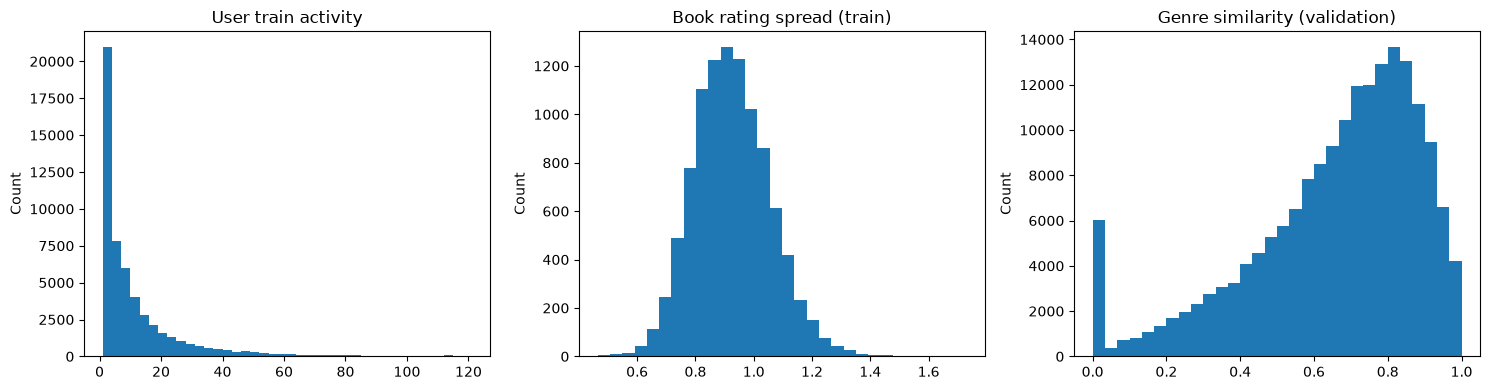

In [11]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
user_features["user_ratings_count"].plot.hist(bins=40, ax=axes[0], title="User train activity")
book_features["book_rating_std"].plot.hist(bins=30, ax=axes[1], title="Book rating spread (train)")
val_features["history_genre_cosine"].plot.hist(bins=30, ax=axes[2], title="Genre similarity (validation)")
for ax in axes:
    ax.set_ylabel("Count")
fig.tight_layout()
plt.show()


Признаки используются ниже в Two Tower: пользовательская башня получает статистики
и жанровый профиль, книжная — статистики книги и жанровые индикаторы. Признаки пары
(косинусное сходство с историей, близость по автору и разница средних оценок)
остаются доступными для будущего ранжировщика: они зависят сразу от пользователя
и книги и не передаются в независимые башни. Улучшение качества нужно проверять
сравнением режимов `use_features=True` и `use_features=False` на одном разбиении.


1.5. recommend_popular

In [12]:
class recommend_popular_recomemder:
    def __init__(self, train_df, ):
        self.user_history = train_df.groupby("user_id")["book_id"].agg(set).to_dict()
        self.global_mean = train_df["rating"].mean()
        self.m = 50

        self.book_popularity = (
            train_df.groupby("book_id")
            .agg(
                mean_rating=("rating", "mean"),
                ratings_count=("rating", "count")
            )
            .reset_index()
        )

        self.book_popularity["score"] = (
        self.book_popularity["ratings_count"]
        / (self.book_popularity["ratings_count"] + self.m)
        * self.book_popularity["mean_rating"]
        +
        self.m / (self.book_popularity["ratings_count"] + self.m)
        * self.global_mean
    )
        self.book_popularity = self.book_popularity.sort_values(
            "score", ascending=False, kind="stable"
        )


    def recommend(self, user_id, N=10):
        if N <= 0:
            return []
        seen = self.user_history.get(user_id, set())

        candidates = self.book_popularity[
            ~self.book_popularity["book_id"].isin(seen)
        ].head(N)

        return [
            {
                "book_id": int(row.book_id),
                "score": float(row.score)
            }
            for row in candidates.itertuples()
    ]


In [13]:
popularity_model = recommend_popular_recomemder(train_df)
test_user = 1
print(f'Рекомендации для пользовател {test_user}')
print(popularity_model.recommend(test_user,10))

Рекомендации для пользовател 1
[{'book_id': 6920, 'score': 4.3873286535243565}, {'book_id': 6590, 'score': 4.386782474796958}, {'book_id': 5207, 'score': 4.380226839630907}, {'book_id': 9566, 'score': 4.380226839630907}, {'book_id': 7947, 'score': 4.369136732189325}, {'book_id': 4708, 'score': 4.355953277468278}, {'book_id': 6361, 'score': 4.354803110817349}, {'book_id': 6642, 'score': 4.349708483126729}, {'book_id': 1904, 'score': 4.349288607491001}, {'book_id': 4483, 'score': 4.347024706039707}]


1.6 Content_based рекомендации

In [14]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize
import numpy as np

from sklearn.feature_extraction.text import TfidfVectorizer

class content_based_recomender:
    def __init__(self, train_df, df_book_tags, df_books, df_tags):
        self.user_history = train_df.groupby("user_id")["book_id"].agg(set).to_dict()

        # 1. Объединяем теги с их названиями
        self.book_tags = df_book_tags.merge(
            df_tags,
            on="tag_id",
            how="left"
        )

        # 2. Выбираем 10 наиболее значимых тегов для каждой книги
        self.book_tags = (
            self.book_tags
            .sort_values("count", ascending=False)
            .groupby("goodreads_book_id")
            .head(10)
            .copy()
        )

        # 3. Подготавливаем названия тегов
        self.book_tags["tag_name"] = (
            self.book_tags["tag_name"]
            .fillna("")
            .str.replace("-", " ", regex=False)
        )

        # 4. Объединяем теги в одну строку для каждой книги
        self.tags_aggregated = (
            self.book_tags.groupby("goodreads_book_id")["tag_name"]
            .agg(" ".join)
            .reset_index()
        )

        # 5. Создаём таблицу с текстовым описанием книг
        self.books_content = df_books[
            ["id", "book_id", "title", "original_title"]
        ].copy()

        # 6. Объединяем книги с тегами по разным названиям ключа
        self.books_content = self.books_content.merge(
            self.tags_aggregated,
            left_on="book_id",
            right_on="goodreads_book_id",
            how="left"
        )

        # 7. Формируем текст для TF-IDF
        self.books_content["content"] = (
            self.books_content["original_title"]
            .fillna(self.books_content["title"])
            .fillna("")
            + " "
            + self.books_content["tag_name"].fillna("")
        )


        self.tfidf = TfidfVectorizer(
            stop_words="english",
            max_features=20000,
            ngram_range=(1, 2)
        )

        self.tfidf_matrix = self.tfidf.fit_transform(
            self.books_content["content"]
        )

        # TfidfVectorizer уже нормализует строки по L2.
        self.tfidf_transpose = self.tfidf_matrix.T.tocsr()

        self.book_id_to_idx = {
            int(book_id): idx
            for idx, book_id in enumerate(self.books_content["id"])
        }

        self.positive_history = (
            train_df[train_df["rating"] >= 4]
            .groupby("user_id")["book_id"]
            .agg(list)
            .to_dict()
        )


        self.global_mean = train_df["rating"].mean()
        self.m = 50

        self.book_popularity = (
            train_df.groupby("book_id")
            .agg(
                mean_rating=("rating", "mean"),
                ratings_count=("rating", "count")
            )
            .reset_index()
        )

        self.book_popularity["score"] = (
        self.book_popularity["ratings_count"]
        / (self.book_popularity["ratings_count"] + self.m)
        * self.book_popularity["mean_rating"]
        +
        self.m / (self.book_popularity["ratings_count"] + self.m)
        * self.global_mean
    )
        self.book_popularity = self.book_popularity.sort_values(
            "score", ascending=False, kind="stable"
        )


    def recommend_from_top(self, user_id, N=10):
        seen = self.user_history.get(user_id, set())

        candidates = self.book_popularity[
            ~self.book_popularity["book_id"].isin(seen)
        ].head(N)

        return [
            {
                "book_id": int(row.book_id),
                "score": float(row.score)
            }
            for row in candidates.itertuples()
    ]



    def recommend(self, user_id, N=10):
        if N <= 0:
            return []
        liked_books = self.positive_history.get(user_id, [])

        indices = [
            self.book_id_to_idx[book_id]
            for book_id in liked_books
            if book_id in self.book_id_to_idx
        ]

        if not indices:
            return self.recommend_from_top(user_id, N)

        user_profile = np.asarray(
            self.tfidf_matrix[indices].mean(axis=0)
        )

        user_profile = normalize(user_profile)

        scores = (csr_matrix(user_profile) @ self.tfidf_transpose).toarray().ravel()

        seen = self.user_history.get(user_id, set())

        for book_id in seen:
            idx = self.book_id_to_idx.get(book_id)
            if idx is not None:
                scores[idx] = -np.inf

        top_indices = np.argsort(scores)[::-1][:N]

        return [
            {
                "book_id": int(self.books_content.iloc[idx]["id"]),
                "score": float(scores[idx])
            }
            for idx in top_indices
            if np.isfinite(scores[idx])
        ]

In [15]:
content_model = content_based_recomender( train_df, df_book_tags, df_books, df_tags)
test_user = 1
print(f'Рекомендации для пользовател {test_user}')
print(content_model.recommend(test_user,10))

Рекомендации для пользовател 1
[{'book_id': 6920, 'score': 4.3873286535243565}, {'book_id': 6590, 'score': 4.386782474796958}, {'book_id': 5207, 'score': 4.380226839630907}, {'book_id': 9566, 'score': 4.380226839630907}, {'book_id': 7947, 'score': 4.369136732189325}, {'book_id': 4708, 'score': 4.355953277468278}, {'book_id': 6361, 'score': 4.354803110817349}, {'book_id': 6642, 'score': 4.349708483126729}, {'book_id': 1904, 'score': 4.349288607491001}, {'book_id': 4483, 'score': 4.347024706039707}]


1.7 Коллаборативная фильтрация

In [16]:


from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix

class cb_item_recomennder:
    def __init__(self, train_df, df_books):
        self.user_history = train_df.groupby("user_id")["book_id"].agg(set).to_dict()
        self.user_ids = np.sort(train_df["user_id"].unique())
        self.book_ids = np.sort(df_books["id"].unique())

        self.user_to_idx = {
            user_id: idx
            for idx, user_id in enumerate(self.user_ids)
        }

        self.book_to_idx = {
            book_id: idx
            for idx, book_id in enumerate(self.book_ids)
        }

        self.rows = train_df["user_id"].map(self.user_to_idx).to_numpy()
        self.cols = train_df["book_id"].map(self.book_to_idx).to_numpy()

        self.interaction_matrix = csr_matrix(
            (
                train_df["rating"].to_numpy(dtype=np.float32),
                (self.rows, self.cols)
            ),
            shape=(len(self.user_ids), len(self.book_ids)),
            dtype=np.float32
        )


        self.item_matrix = self.interaction_matrix.T.tocsr()

        self.item_similarity = cosine_similarity(
            self.item_matrix,
            dense_output=False
        )

        self.item_similarity.setdiag(0)
        self.item_similarity.eliminate_zeros()


        self.global_mean = train_df["rating"].mean()
        self.m = 50

        self.book_popularity = (
            train_df.groupby("book_id")
            .agg(
                mean_rating=("rating", "mean"),
                ratings_count=("rating", "count")
            )
            .reset_index()
        )

        self.book_popularity["score"] = (
        self.book_popularity["ratings_count"]
        / (self.book_popularity["ratings_count"] + self.m)
        * self.book_popularity["mean_rating"]
        +
        self.m / (self.book_popularity["ratings_count"] + self.m)
        * self.global_mean
    )
        self.book_popularity = self.book_popularity.sort_values(
            "score", ascending=False, kind="stable"
        )


    def recommend_from_top(self, user_id, N=10):
        seen = self.user_history.get(user_id, set())

        candidates = self.book_popularity[
            ~self.book_popularity["book_id"].isin(seen)
        ].head(N)

        return [
            {
                "book_id": int(row.book_id),
                "score": float(row.score)
            }
            for row in candidates.itertuples()
    ]



    def recommend(self,user_id, N=10):
        if N <= 0:
            return []
        if user_id not in self.user_to_idx:
            return self.recommend_from_top(user_id, N)

        user_idx = self.user_to_idx[user_id]
        user_ratings = self.interaction_matrix.getrow(user_idx)
        # Матрица cosine similarity симметрична: обходим только оценки пользователя.
        weighted_scores = (user_ratings @ self.item_similarity).toarray().ravel()

        observed = user_ratings.copy()
        observed.data = np.ones_like(observed.data)
        normalizer = (observed @ self.item_similarity).toarray().ravel()
        scores = np.divide(
            weighted_scores,
            normalizer,
            out=np.zeros_like(weighted_scores),
            where=normalizer > 0,
        )
        scores[normalizer <= 0] = -np.inf
        scores[user_ratings.indices] = -np.inf

        valid_indices = np.where(np.isfinite(scores))[0]
        top_indices = valid_indices[
            np.argsort(scores[valid_indices])[::-1][:N]
        ]
        return [
            {"book_id": int(self.book_ids[idx]), "score": float(scores[idx])}
            for idx in top_indices
        ]


In [17]:
item_cf_model = cb_item_recomennder( train_df, df_books)
test_user = 1
print(f'Рекомендации для пользовател {test_user}')
print(item_cf_model.recommend(test_user,10))

Рекомендации для пользовател 1
[{'book_id': 1708, 'score': 3.000000238418579}, {'book_id': 1734, 'score': 3.000000238418579}, {'book_id': 9451, 'score': 3.000000238418579}, {'book_id': 9510, 'score': 3.000000238418579}, {'book_id': 9632, 'score': 3.000000238418579}, {'book_id': 1778, 'score': 3.000000238418579}, {'book_id': 2147, 'score': 3.000000238418579}, {'book_id': 2666, 'score': 3.000000238418579}, {'book_id': 2809, 'score': 3.000000238418579}, {'book_id': 2924, 'score': 3.000000238418579}]


In [18]:
from surprise import SVD, Dataset, Reader


class svd_recommender:
    def __init__(self, train_df, df_books, n_epochs=50, random_state=42):
        self.reader = Reader(rating_scale=(1, 5))

        dataset = Dataset.load_from_df(
            train_df[["user_id", "book_id", "rating"]],
            self.reader
        )

        self.trainset = dataset.build_full_trainset()

        self.svd_model = SVD(
            n_factors=50,
            n_epochs=n_epochs,
            lr_all=0.005,
            reg_all=0.02,
            random_state=random_state
        )

        self.svd_model.fit(self.trainset)

        self.user_ids = np.sort(train_df["user_id"].unique())
        self.book_ids = np.sort(df_books["id"].unique())

        self.user_history = (
        train_df.groupby("user_id")["book_id"]
        .agg(set)
        .to_dict()
)

        # Выровненные по каталогу факторы; неизвестные книги имеют нулевые факторы.
        self.catalog_factors = np.zeros((len(self.book_ids), self.svd_model.n_factors))
        self.catalog_bias = np.zeros(len(self.book_ids))
        book_to_idx = {int(b): i for i, b in enumerate(self.book_ids)}
        for inner in self.trainset.all_items():
            idx = book_to_idx[int(self.trainset.to_raw_iid(inner))]
            self.catalog_factors[idx] = self.svd_model.qi[inner]
            self.catalog_bias[idx] = self.svd_model.bi[inner]
        self.user_to_inner = {self.trainset.to_raw_uid(i): i
                              for i in self.trainset.all_users()}

    def recommend(self, user_id, N=10):
        if N <= 0:
            return []
        scores = self.trainset.global_mean + self.catalog_bias
        inner = self.user_to_inner.get(user_id)
        if inner is not None:
            # Та же формула Surprise SVD, сразу для всего каталога.
            scores = scores + self.svd_model.bu[inner] + np.einsum(
                "ij,j->i", self.catalog_factors, self.svd_model.pu[inner]
            )
        scores = np.clip(scores, *self.trainset.rating_scale)
        seen = self.user_history.get(user_id, set())
        scores[np.isin(self.book_ids, list(seen))] = -np.inf
        valid = np.flatnonzero(np.isfinite(scores))
        top = valid[np.argsort(-scores[valid], kind="stable")[:N]]
        return [{"book_id": int(self.book_ids[i]), "score": float(scores[i])} for i in top]


svd_model = svd_recommender(train_df, df_books)
test_user = 1
print(f'Рекомендации для пользовател {test_user}')
print(svd_model.recommend(test_user,10))

Рекомендации для пользовател 1
[{'book_id': 862, 'score': 4.764967592471308}, {'book_id': 9842, 'score': 4.7583912022493795}, {'book_id': 4653, 'score': 4.708216162799337}, {'book_id': 6642, 'score': 4.657524939256698}, {'book_id': 6902, 'score': 4.639626840413256}, {'book_id': 6590, 'score': 4.620286039264171}, {'book_id': 964, 'score': 4.614640806266243}, {'book_id': 9566, 'score': 4.610917923613239}, {'book_id': 7947, 'score': 4.600114995670601}, {'book_id': 5207, 'score': 4.579069203198443}]


Метрики

In [19]:
import numpy as np

def precision_at_k(actual, predicted, k=10):
    if k <= 0:
        return 0.0

    actual = set(actual)
    predicted = list(dict.fromkeys(predicted))[:k]

    hits = len(actual.intersection(predicted))

    return hits / k


def recall_at_k(actual, predicted, k=10):
    actual = set(actual)

    if not actual or k <= 0:
        return 0.0

    predicted = list(dict.fromkeys(predicted))[:k]

    hits = len(actual.intersection(predicted))

    return hits / len(actual)


def ndcg_at_k(actual, predicted, k=10):
    actual = set(actual)

    if not actual or k <= 0:
        return 0.0

    predicted = list(dict.fromkeys(predicted))[:k]

    relevance = np.array([
        1 if book_id in actual else 0
        for book_id in predicted
    ])

    positions = np.arange(1, len(relevance) + 1)

    dcg = np.sum(
        relevance / np.log2(positions + 1)
    )

    ideal_hits = min(len(actual), k)

    ideal_positions = np.arange(1, ideal_hits + 1)

    idcg = np.sum(
        1 / np.log2(ideal_positions + 1)
    )

    return float(dcg / idcg)

def evaluate_model(recommend_fn, relevant, k=10, verbose=False):
    from time import perf_counter

    results = []
    started = perf_counter()

    for index, (user_id, actual) in enumerate(relevant.items(), start=1):
        raw_predicted = recommend_fn(user_id, N=k)
        predicted = [rec["book_id"] for rec in raw_predicted]

        results.append({
            "user_id": user_id,
            "precision": precision_at_k(actual, predicted, k),
            "recall": recall_at_k(actual, predicted, k),
            "ndcg": ndcg_at_k(actual, predicted, k),
        })

        if verbose and (index % 500 == 0 or index == len(relevant)):
            elapsed = perf_counter() - started
            eta = elapsed / index * (len(relevant) - index)
            print(f"{index}/{len(relevant)} пользователей | {elapsed:.1f} с | осталось ≈ {eta:.1f} с", flush=True)

    return pd.DataFrame(
        results,
        columns=["user_id", "precision", "recall", "ndcg"],
    )

In [20]:
models = {
    "Popularity": popularity_model.recommend,
    "Content-Based": content_model.recommend,
    "Item-Based CF": item_cf_model.recommend,
    "SVD": svd_model.recommend,
}


def evaluate_model(recommend_fn, relevant, k=10, verbose=False):
    from time import perf_counter

    results = []
    started = perf_counter()

    for index, (user_id, actual) in enumerate(relevant.items(), start=1):
        raw_predicted = recommend_fn(user_id, N=k)
        predicted = [rec["book_id"] for rec in raw_predicted]

        results.append({
            "user_id": user_id,
            "precision": precision_at_k(actual, predicted, k),
            "recall": recall_at_k(actual, predicted, k),
            "ndcg": ndcg_at_k(actual, predicted, k),
        })

        if verbose and (index % 500 == 0 or index == len(relevant)):
            elapsed = perf_counter() - started
            eta = elapsed / index * (len(relevant) - index)
            print(f"{index}/{len(relevant)} пользователей | {elapsed:.1f} с | осталось ≈ {eta:.1f} с", flush=True)

    return pd.DataFrame(
        results,
        columns=["user_id", "precision", "recall", "ndcg"],
    )


# Базовые модели обучены на train_df; сравниваем их на val.
# Итоговая оценка всех моделей на test находится после подбора весов.
evaluation_relevant = val_relevant

val_comparison_results = []

for model_name, recommend_fn in models.items():
    print(f"Оценка {model_name}: {len(evaluation_relevant)} пользователей", flush=True)
    metrics = evaluate_model(
        recommend_fn,
        relevant=evaluation_relevant,
        k=10,
        verbose=True,
    )

    val_comparison_results.append({
        "Model": model_name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean(),
    })

val_comparison_df = pd.DataFrame(val_comparison_results)

display(
    val_comparison_df
    .sort_values("nDCG@10", ascending=False)
    .reset_index(drop=True)
)

Оценка Popularity: 36825 пользователей
500/36825 пользователей | 0.4 с | осталось ≈ 32.0 с
1000/36825 пользователей | 0.9 с | осталось ≈ 31.0 с
1500/36825 пользователей | 1.3 с | осталось ≈ 30.6 с
2000/36825 пользователей | 1.8 с | осталось ≈ 30.7 с
2500/36825 пользователей | 2.2 с | осталось ≈ 30.4 с
3000/36825 пользователей | 2.7 с | осталось ≈ 30.0 с
3500/36825 пользователей | 3.1 с | осталось ≈ 29.6 с
4000/36825 пользователей | 3.5 с | осталось ≈ 29.0 с
4500/36825 пользователей | 4.0 с | осталось ≈ 28.5 с
5000/36825 пользователей | 4.4 с | осталось ≈ 28.1 с
5500/36825 пользователей | 4.9 с | осталось ≈ 27.7 с
6000/36825 пользователей | 5.3 с | осталось ≈ 27.2 с
6500/36825 пользователей | 5.7 с | осталось ≈ 26.8 с
7000/36825 пользователей | 6.2 с | осталось ≈ 26.3 с
7500/36825 пользователей | 6.6 с | осталось ≈ 25.8 с
8000/36825 пользователей | 7.0 с | осталось ≈ 25.3 с
8500/36825 пользователей | 7.5 с | осталось ≈ 24.9 с
9000/36825 пользователей | 7.9 с | осталось ≈ 24.5 с
9500/368

,Model,Precision@10,Recall@10,nDCG@10
0,Content-Based,0.033656,0.128933,0.094782
1,Item-Based CF,0.000747,0.005104,0.002380
2,SVD,0.000578,0.001310,0.000993
3,Popularity,0.000448,0.001554,0.000963


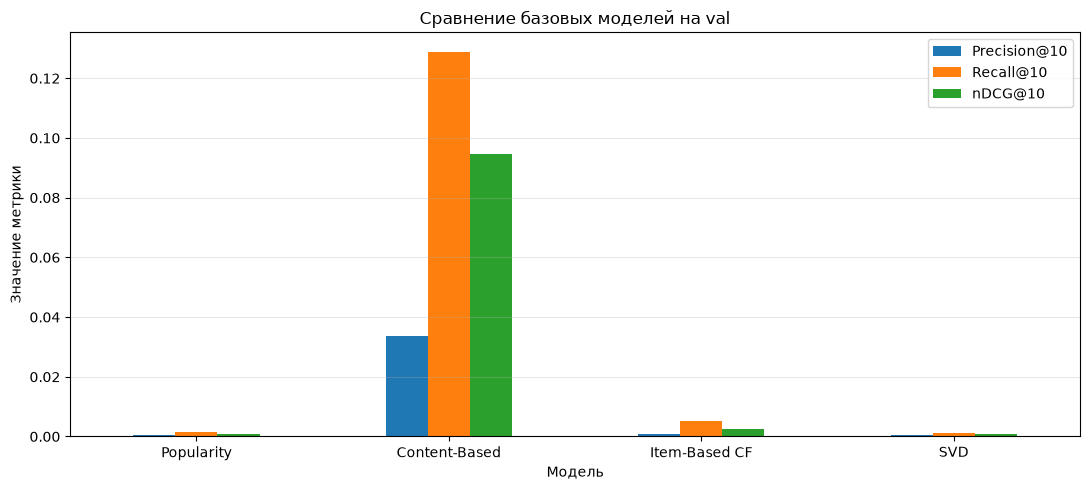

In [21]:
import matplotlib.pyplot as plt

val_comparison_df.set_index("Model")[
    ["Precision@10", "Recall@10", "nDCG@10"]
].plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

plt.title("Сравнение базовых моделей на val")
plt.xlabel("Модель")
plt.ylabel("Значение метрики")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Two Tower с расширенными признаками

- **Башня пользователя:** ID-эмбеддинг + число и статистики оценок, активность,
  разнообразие жанров и доли каждого жанра в положительной истории train.
- **Башня книги:** ID-эмбеддинг + популярность, средняя и сглаженная оценка,
  разброс и энтропия оценок, число жанров и жанровые индикаторы.
- После конкатенации каждая башня использует `Linear → ReLU → Linear → L2`.
  Итоговый score — скалярное произведение нормированных представлений.

StandardScaler обучается только на train-признаках. Для положительных train-пар
в обе башни передаются **leave-one-out** признаки: собственная оценка не включается
в статистики, жанровый профиль и глобальный prior. Отрицательные книги выбираются
вне всей train-истории пользователя; в их статистиках также исключается целевая
оценка из глобального prior. При выдаче векторы пользователей и книг
кэшируются по полной train-истории; матрицы строятся пакетами.

Обучение использует BPR loss. Лучшая эпоха выбирается по validation nDCG; test
не используется при обучении. Неизвестному пользователю выдаётся популярность.
Как и в исходном варианте, книги без train-взаимодействий исключаются из персональной
выдачи: их ID-эмбеддинги не обучены. `use_features=False` отключает числовые входы
для сравнения с моделью только по ID.

После обучения модель передаётся в `base_models["two_tower"]` и участвует
в гибридных кандидатах, начальных весах и последующей оптимизации.


In [22]:
import copy

import torch
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset


class TwoTower(nn.Module):
    """Каждая башня получает ID-эмбеддинг и собственные числовые признаки."""

    def __init__(
        self,
        n_users,
        n_books,
        embedding_dim=64,
        output_dim=32,
        user_feature_dim=0,
        book_feature_dim=0,
    ):
        super().__init__()
        self.user_feature_dim = user_feature_dim
        self.book_feature_dim = book_feature_dim
        self.user_embedding = nn.Embedding(n_users, embedding_dim)
        self.book_embedding = nn.Embedding(n_books, embedding_dim)

        def tower(feature_dim):
            return nn.Sequential(
                nn.Linear(embedding_dim + feature_dim, embedding_dim),
                nn.ReLU(),
                nn.Linear(embedding_dim, output_dim),
            )

        self.user_tower = tower(user_feature_dim)
        self.book_tower = tower(book_feature_dim)

    def encode_user(self, users, features=None):
        embedded = self.user_embedding(users)
        if self.user_feature_dim:
            if features is None:
                raise ValueError("Нужны числовые признаки пользователей")
            embedded = torch.cat([embedded, features], dim=-1)
        return F.normalize(self.user_tower(embedded), dim=-1)

    def encode_book(self, books, features=None):
        embedded = self.book_embedding(books)
        if self.book_feature_dim:
            if features is None:
                raise ValueError("Нужны числовые признаки книг")
            embedded = torch.cat([embedded, features], dim=-1)
        return F.normalize(self.book_tower(embedded), dim=-1)

    def forward(self, users, books, user_features=None, book_features=None):
        return (
            self.encode_user(users, user_features)
            * self.encode_book(books, book_features)
        ).sum(dim=-1)


class TwoTowerRecommender:
    def __init__(
        self,
        train_df,
        df_books,
        train_features=None,
        user_features=None,
        book_features=None,
        use_features=True,
        embedding_dim=64,
        output_dim=32,
        random_state=42,
        device=None,
    ):
        if train_df.empty or df_books.empty:
            raise ValueError("Нужны непустые train и каталог")
        if not train_df["book_id"].isin(df_books["id"]).all():
            raise ValueError("Книги train должны присутствовать в books.id")
        if df_books["id"].duplicated().any():
            raise ValueError("books.id должен быть уникальным")
        torch.manual_seed(random_state)
        self.random_state = random_state
        self.use_features = use_features
        self.rng = np.random.default_rng(random_state)
        self.device = torch.device(
            device or ("cuda" if torch.cuda.is_available() else "cpu")
        )
        self.user_ids = np.sort(train_df["user_id"].unique())
        self.book_ids = np.sort(df_books["id"].unique())
        self.user_to_idx = {u: i for i, u in enumerate(self.user_ids)}
        self.book_to_idx = {b: i for i, b in enumerate(self.book_ids)}
        self.user_history = train_df.groupby("user_id")["book_id"].agg(set).to_dict()
        self.known_books = np.isin(self.book_ids, train_df["book_id"].unique())
        self.popular = train_df.groupby("book_id").size().sort_values(ascending=False)
        users = train_df["user_id"].map(self.user_to_idx).to_numpy(dtype=np.int64)
        books = train_df["book_id"].map(self.book_to_idx).to_numpy(dtype=np.int64)
        self.seen_keys = np.unique(users * len(self.book_ids) + books)
        can_sample = (
            train_df["user_id"]
            .map(
                {
                    u: len(seen) < len(self.book_ids)
                    for u, seen in self.user_history.items()
                }
            )
            .to_numpy()
        )
        positive = (train_df["rating"].to_numpy() >= 4) & can_sample
        self.pairs = np.column_stack((users[positive], books[positive]))
        self.positive_ratings = train_df["rating"].to_numpy()[positive]
        self.train_size = len(train_df)
        self.train_rating_sum = float(train_df["rating"].sum())
        if not len(self.pairs):
            raise ValueError("Нужны положительные train-пары и непрочитанные книги")

        self.user_feature_columns = []
        self.book_feature_columns = []
        self.user_scaler = self.book_scaler = None
        full_user = np.empty((len(self.user_ids), 0), dtype=np.float32)
        full_book = np.empty((len(self.book_ids), 0), dtype=np.float32)
        pair_user = np.empty((len(self.pairs), 0), dtype=np.float32)
        pair_book = np.empty((len(self.pairs), 0), dtype=np.float32)
        if use_features:
            if any(
                table is None
                for table in [train_features, user_features, book_features]
            ):
                raise ValueError(
                    "Передайте train_features (leave-one-out), user_features и book_features"
                )
            if (
                user_features["user_id"].duplicated().any()
                or book_features["book_id"].duplicated().any()
            ):
                raise ValueError("Таблицы признаков должны содержать уникальные ID")
            if train_features.duplicated(["user_id", "book_id"]).any():
                raise ValueError("В train_features должны быть уникальные пары")
            self.user_feature_columns = [
                c
                for c in user_features.select_dtypes(include="number").columns
                if c.startswith("user_") and c != "user_id"
            ]
            self.book_feature_columns = [
                c
                for c in book_features.select_dtypes(include="number").columns
                if (c.startswith("book_") and c != "book_id") or c.startswith("genre_")
            ]
            if not self.user_feature_columns or not self.book_feature_columns:
                raise ValueError("Нужны числовые признаки обеих башен")
            pair_keys = pd.MultiIndex.from_frame(train_df[["user_id", "book_id"]])
            aligned = train_features.set_index(["user_id", "book_id"]).reindex(
                pair_keys
            )
            if len(train_features) != len(train_df) or not np.array_equal(
                aligned["rating"].to_numpy(), train_df["rating"].to_numpy()
            ):
                raise ValueError(
                    "train_features должны соответствовать обучающей выборке"
                )
            # Эти счётчики позволяют обнаружить случайную передачу full-train вместо LOO.
            expected_user_counts = (
                train_df["user_id"].map(train_df.groupby("user_id").size()).to_numpy()
                - 1
            )
            expected_book_counts = (
                train_df["book_id"].map(train_df.groupby("book_id").size()).to_numpy()
                - 1
            )
            if not (
                np.array_equal(aligned["user_ratings_count"], expected_user_counts)
                and np.array_equal(aligned["book_ratings_count"], expected_book_counts)
            ):
                raise ValueError("Для обучения нужны признаки leave-one-out")
            full_user = user_features.set_index("user_id").reindex(self.user_ids)[
                self.user_feature_columns
            ]
            full_book = book_features.set_index("book_id").reindex(self.book_ids)[
                self.book_feature_columns
            ]
            loo_user = aligned[self.user_feature_columns]
            loo_book = aligned[self.book_feature_columns]
            for frame in [full_user, full_book, loo_user, loo_book]:
                if not np.isfinite(frame.to_numpy()).all():
                    raise ValueError("Все ID должны иметь конечные числовые признаки")
            # Fit только на обучающих строках. Тот же scaler применяется при выдаче.
            self.raw_book_features = full_book.to_numpy(copy=True)
            self.user_scaler = StandardScaler().fit(loo_user)
            self.book_scaler = StandardScaler().fit(loo_book)
            full_user = self.user_scaler.transform(full_user).astype(np.float32)
            full_book = self.book_scaler.transform(full_book).astype(np.float32)
            pair_user = self.user_scaler.transform(
                loo_user.iloc[np.flatnonzero(positive)]
            ).astype(np.float32)
            pair_book = self.book_scaler.transform(
                loo_book.iloc[np.flatnonzero(positive)]
            ).astype(np.float32)

        # При выдаче используются полные train-профили; при обучении — LOO-профили.
        self.user_feature_tensor = torch.tensor(
            full_user, dtype=torch.float32, device=self.device
        )
        self.book_feature_tensor = torch.tensor(
            full_book, dtype=torch.float32, device=self.device
        )
        self.pair_user_features = torch.tensor(pair_user, dtype=torch.float32)
        self.pair_book_features = torch.tensor(pair_book, dtype=torch.float32)
        self.network = TwoTower(
            len(self.user_ids),
            len(self.book_ids),
            embedding_dim,
            output_dim,
            len(self.user_feature_columns),
            len(self.book_feature_columns),
        ).to(self.device)
        self._cache_vectors()

    @torch.no_grad()
    def _cache_vectors(self, batch_size=4096):
        self.network.eval()

        def encode_all(size, encoder, features):
            vectors = []
            for start in range(0, size, batch_size):
                stop = min(start + batch_size, size)
                indices = torch.arange(start, stop, device=self.device)
                vectors.append(encoder(indices, features[start:stop]).cpu().numpy())
            return np.concatenate(vectors)

        self.user_vectors = encode_all(
            len(self.user_ids), self.network.encode_user, self.user_feature_tensor
        )
        self.book_vectors = encode_all(
            len(self.book_ids), self.network.encode_book, self.book_feature_tensor
        )

    def _sample_negatives(self):
        # Не считаем отрицательными и книги с низкими train-оценками пользователя.
        negatives = self.rng.integers(len(self.book_ids), size=len(self.pairs))
        invalid = np.isin(
            self.pairs[:, 0] * len(self.book_ids) + negatives, self.seen_keys
        )
        while invalid.any():
            negatives[invalid] = self.rng.integers(
                len(self.book_ids), size=invalid.sum()
            )
            invalid = np.isin(
                self.pairs[:, 0] * len(self.book_ids) + negatives, self.seen_keys
            )
        return negatives

    def _negative_book_features(self, negatives):
        """И у отрицательной книги исключаем target из глобального prior."""
        if not self.use_features:
            return torch.empty((len(negatives), 0), dtype=torch.float32)
        raw = pd.DataFrame(
            self.raw_book_features[negatives].copy(), columns=self.book_feature_columns
        )
        n = raw["book_ratings_count"].to_numpy()
        old_prior = self.train_rating_sum / self.train_size
        prior = (
            (self.train_rating_sum - self.positive_ratings) / (self.train_size - 1)
            if self.train_size > 1
            else np.full(len(negatives), 3.0)
        )
        raw["book_smoothed_rating"] += 50 * (prior - old_prior) / (n + 50)
        raw.loc[n == 0, "book_mean_rating"] = prior[n == 0]
        raw["book_popularity_share"] = n / max(self.train_size - 1, 1)
        return torch.tensor(self.book_scaler.transform(raw), dtype=torch.float32)

    def fit(self, val_relevant, epochs=5, batch_size=1024, lr=1e-3, k=10):
        if not val_relevant or epochs < 1 or batch_size < 1 or lr <= 0 or k < 1:
            raise ValueError(
                "Нужны непустая val и положительные epochs, batch_size, lr, k"
            )
        optimizer = torch.optim.Adam(
            self.network.parameters(), lr=lr, weight_decay=1e-5
        )
        generator = torch.Generator().manual_seed(self.random_state)
        best_score, best_state, history = -np.inf, None, []
        for epoch in range(1, epochs + 1):
            negatives = self._sample_negatives()
            negative_features = self._negative_book_features(negatives)
            loader = DataLoader(
                TensorDataset(
                    torch.from_numpy(self.pairs[:, 0].copy()),
                    torch.from_numpy(self.pairs[:, 1].copy()),
                    torch.from_numpy(negatives),
                    self.pair_user_features,
                    self.pair_book_features,
                    negative_features,
                ),
                batch_size=batch_size,
                shuffle=True,
                generator=generator,
            )
            self.network.train()
            total_loss = 0.0
            for batch in loader:
                (
                    users,
                    positive,
                    negative,
                    user_features_batch,
                    positive_features,
                    negative_features,
                ) = [x.to(self.device) for x in batch]
                positive_score = self.network(
                    users, positive, user_features_batch, positive_features
                )
                negative_score = self.network(
                    users, negative, user_features_batch, negative_features
                )
                loss = F.softplus((negative_score - positive_score) / 0.1).mean()
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
                total_loss += loss.item() * len(users)
            self._cache_vectors()
            score = float(
                evaluate_model(self.recommend, val_relevant, k=k)["ndcg"].mean()
            )
            if not np.isfinite(score):
                raise ValueError("Validation nDCG должен быть конечным")
            history.append(
                {
                    "epoch": epoch,
                    "loss": total_loss / len(self.pairs),
                    f"val_nDCG@{k}": score,
                }
            )
            if score > best_score:
                best_score, self.best_epoch = score, epoch
                best_state = copy.deepcopy(self.network.state_dict())
            print(
                f"Epoch {epoch}: loss={history[-1]['loss']:.4f}, val nDCG@{k}={score:.4f}"
            )
        self.network.load_state_dict(best_state)
        self._cache_vectors()
        self.history = pd.DataFrame(history)
        return self

    def recommend(self, user_id, N=10):
        if N <= 0:
            return []
        seen = self.user_history.get(user_id, set())
        if user_id not in self.user_to_idx:
            return [
                {"book_id": int(b), "score": float(count)}
                for b, count in self.popular.items()
                if b not in seen
            ][:N]
        scores = self.book_vectors @ self.user_vectors[self.user_to_idx[user_id]]
        scores[~self.known_books | np.isin(self.book_ids, list(seen))] = -np.inf
        valid = np.flatnonzero(np.isfinite(scores))
        top = valid[np.lexsort((self.book_ids[valid], -scores[valid]))[:N]]
        return [
            {"book_id": int(self.book_ids[i]), "score": float(scores[i])} for i in top
        ]


In [23]:
two_tower_model = TwoTowerRecommender(
    train_df, df_books,
    train_features=train_features,
    user_features=user_features,
    book_features=book_features,
    use_features=True,
    random_state=RANDOM_STATE,
)
print("Признаки башни пользователя:", two_tower_model.user_feature_columns)
print("Признаки башни книги:", two_tower_model.book_feature_columns)
print("Размер входа пользователя:", two_tower_model.network.user_tower[0].in_features)
print("Размер входа книги:", two_tower_model.network.book_tower[0].in_features)
two_tower_model.fit(val_relevant, epochs=5, batch_size=1024)
display(two_tower_model.history)
print("Лучшая эпоха по val:", two_tower_model.best_epoch)
display(pd.DataFrame(two_tower_model.recommend(user_id=1, N=10)))

# Для абляции создайте отдельную модель с use_features=False и тем же seed,
# обучите её с теми же epochs/batch_size и сравните на одной validation-выборке.


Признаки башни пользователя: ['user_ratings_count', 'user_mean_rating', 'user_rating_std', 'user_positive_share', 'user_log_activity', 'user_history_genre_count', 'user_genre_fantasy', 'user_genre_science_fiction', 'user_genre_romance', 'user_genre_mystery', 'user_genre_thriller', 'user_genre_horror', 'user_genre_historical', 'user_genre_young_adult', 'user_genre_children', 'user_genre_classics', 'user_genre_nonfiction', 'user_genre_biography', 'user_genre_poetry', 'user_genre_comics']
Признаки башни книги: ['book_ratings_count', 'book_mean_rating', 'book_rating_std', 'book_positive_share', 'book_log_activity', 'book_popularity_share', 'book_smoothed_rating', 'book_rating_entropy', 'book_distinct_ratings', 'book_genre_count', 'genre_fantasy', 'genre_science_fiction', 'genre_romance', 'genre_mystery', 'genre_thriller', 'genre_horror', 'genre_historical', 'genre_young_adult', 'genre_children', 'genre_classics', 'genre_nonfiction', 'genre_biography', 'genre_poetry', 'genre_comics']
Размер

,epoch,loss,val_nDCG@10
0,1,0.466026,0.011200
1,2,0.366554,0.014265
2,3,0.334207,0.017469
3,4,0.294797,0.019555
4,5,0.261676,0.021536


Лучшая эпоха по val: 5


,book_id,score
0,8882,0.870595
1,9111,0.861683
2,7189,0.857134
3,8903,0.851719
4,5990,0.851430
5,5730,0.848518
6,9356,0.848042
7,9674,0.847295
8,9908,0.841256
9,7063,0.840795


Этап 2. Построение гибридной системы

Стратегия объединения моделей:
Взвешенное усреднение предсказаний разных моделей.
Разделение пользователей по типам (новые/активные).
Комбинирование персонализированных и популярных рекомендаций.
Система генерации кандидатов:
Объединение рекомендаций от всех моделей в общий пул.
Балансировка между разнообразием и релевантностью.
Фильтрация уже прочитанных книг.

Теперь гибрид использует пять моделей: Popularity, Content-Based, Item-Based CF,
SVD и обученную выше Two Tower. Кандидаты нейросети включаются в общий пул,
её score нормируется так же, как у остальных моделей, а вес подбирается Optuna
отдельно для каждой группы пользователей. Все гибриды переиспользуют одни
обученные экземпляры. Классический гибрид из четырёх моделей оставлен для сравнения.


In [24]:
import numpy as np
import pandas as pd

def normalize_scores(recommendations):
    if not recommendations:
        return {}

    df = pd.DataFrame(recommendations)

    min_score = df["score"].min()
    max_score = df["score"].max()

    if np.isclose(min_score, max_score):
        df["normalized_score"] = 1.0
    else:
        df["normalized_score"] = (
            (df["score"] - min_score)
            / (max_score - min_score)
        )

    return dict(zip(
        df["book_id"],
        df["normalized_score"]
    ))

In [25]:
DEFAULT_WEIGHTS = {
    "pop": 0.08,
    "content": 0.16,
    "item": 0.24,
    "svd": 0.32,
    "two_tower": 0.20,
}


class HybridRecommender:
    def __init__(self, train_df, models):
        # Все модели уже обучены: здесь только объединяем их рекомендации.
        self.models = dict(models)
        if not self.models or not set(self.models).issubset(DEFAULT_WEIGHTS):
            raise ValueError("Нужны модели с ключами pop/content/item/svd/two_tower")
        total = sum(DEFAULT_WEIGHTS[name] for name in self.models)
        self.default_weights = {name: DEFAULT_WEIGHTS[name] / total for name in self.models}
        self.user_history = train_df.groupby("user_id")["book_id"].agg(set).to_dict()

    def normalize_scores(self, recommendations):
        if not recommendations:
            return {}

        df = pd.DataFrame(recommendations)

        min_score = df["score"].min()
        max_score = df["score"].max()

        if np.isclose(min_score, max_score):
            df["normalized_score"] = 1.0
        else:
            df["normalized_score"] = (
                (df["score"] - min_score)
                / (max_score - min_score)
            )

        return dict(zip(
            df["book_id"],
            df["normalized_score"]
        ))

    def recommend(self, user_id, N=10, weights=None, candidates_k=100):
        if N <= 0:
            return []
        if candidates_k < 1:
            raise ValueError("candidates_k должен быть положительным")
        candidates_k = max(candidates_k, N)
        weights = dict(self.default_weights if weights is None else weights)

        if set(weights) != set(self.models):
            raise ValueError(
                f"Веса должны содержать ключи: {list(self.models)}"
            )

        if any(not np.isfinite(w) or w < 0 for w in weights.values()):
            raise ValueError(
                "Веса должны быть конечными неотрицательными числами"
            )

        if not np.isclose(sum(weights.values()), 1.0):
            raise ValueError("Сумма весов должна равняться 1")

        # Получаем рекомендации базовых моделей
        recommendations = {
            name: model.recommend(user_id, N=candidates_k)
            for name, model in self.models.items()
        }

        # Используем существующую функцию normalize_scores:
        # она должна возвращать словарь {book_id: normalized_score}
        normalized = {
            name: self.normalize_scores(recs)
            for name, recs in recommendations.items()
        }

        candidate_ids = set().union(
            *(scores.keys() for scores in normalized.values())
        )

        # Исключаем прочитанные книги
        seen = self.user_history.get(user_id, set())
        candidate_ids -= seen

        results = []

        for book_id in candidate_ids:
            score = sum(
                weights[name] * normalized[name].get(book_id, 0.0)
                for name in self.models
            )

            results.append({
                "book_id": int(book_id),
                "score": float(score),
            })

        results.sort(key=lambda rec: (-rec["score"], rec["book_id"]))

        return results[:N]

In [26]:
base_models = {
    "pop": popularity_model,
    "content": content_model,
    "item": item_cf_model,
    "svd": svd_model,
    "two_tower": two_tower_model,
}
hybrid_model = HybridRecommender(train_df, models=base_models)
# Классический вариант нужен для честного сравнения вклада нейросети.
classical_hybrid = HybridRecommender(
    train_df, models={name: model for name, model in base_models.items() if name != "two_tower"}
)
display(pd.DataFrame(hybrid_model.recommend(user_id=1, N=10)))


,book_id,score
0,862,0.463052
1,9842,0.462592
2,6590,0.442528
3,9566,0.425119
4,6642,0.416817
5,7947,0.399737
6,5207,0.399441
7,6920,0.383832
8,5447,0.342092
9,7569,0.329383


Адаптивная модель

In [27]:
ADAPTIVE_WEIGHTS = {
    "new": {
        "pop": 0.65,
        "content": 0.25,
        "item": 0.05,
        "svd": 0.05,
    },
    "regular": {
        "pop": 0.15,
        "content": 0.35,
        "item": 0.25,
        "svd": 0.25,
    },
    "active": {
        "pop": 0.05,
        "content": 0.15,
        "item": 0.35,
        "svd": 0.45,
    },
}


class AdaptiveHybridRecommender(HybridRecommender):
    def __init__(self, train_df, models, adaptive_weights=None):
        # Инициализируем базовые модели и историю пользователей
        super().__init__(train_df, models=models)

        self.user_activity = (
            train_df.groupby("user_id")
            .size()
            .to_dict()
        )

        if adaptive_weights is None:
            # 20% изначально отдаём нейросети; остальные веса сохраняют прежние пропорции.
            source_weights = {
                group: {**{name: 0.8 * weight for name, weight in weights.items()},
                        "two_tower": 0.2}
                for group, weights in ADAPTIVE_WEIGHTS.items()
            }
            self.adaptive_weights = {}
            for group, weights in source_weights.items():
                total = sum(weights[name] for name in self.models)
                self.adaptive_weights[group] = {name: weights[name] / total for name in self.models}
        else:
            self.adaptive_weights = {group: dict(weights) for group, weights in adaptive_weights.items()}

    def get_user_type(self, user_id):
        n_ratings = self.user_activity.get(user_id, 0)

        if n_ratings < 5:
            return "new"
        elif n_ratings < 50:
            return "regular"
        else:
            return "active"

    def recommend(self, user_id, N=10, weights=None, candidates_k=100):
        # Явно переданные веса имеют приоритет
        if weights is None:
            user_type = self.get_user_type(user_id)
            weights = self.adaptive_weights[user_type]

        # Объединение рекомендаций и проверку весов выполняет родитель
        return super().recommend(
            user_id=user_id,
            N=N,
            weights=weights,
            candidates_k=candidates_k,
        )

In [28]:
adaprive_hybrid_model = AdaptiveHybridRecommender(train_df, models=base_models)

adaptive_recs = adaprive_hybrid_model.recommend(user_id=1, N=10)
display(pd.DataFrame(adaptive_recs))

,book_id,score
0,6590,0.742955
1,6920,0.737979
2,9566,0.712445
3,5207,0.709235
4,7947,0.661340
5,6361,0.583726
6,4708,0.582555
7,6642,0.579504
8,1904,0.548438
9,4483,0.538437


In [29]:
import optuna


def optimize_adaptive_weights(model, val_relevant, n_trials=30, k=10,
                              candidates_k=100, random_state=42):
    if n_trials < 1:
        raise ValueError("n_trials должен быть положительным")
    best_weights = {group: dict(w) for group, w in model.adaptive_weights.items()}
    results = []
    names = list(model.models)

    for user_type in ("new", "regular", "active"):
        relevant = {u: actual for u, actual in val_relevant.items()
                    if model.get_user_type(u) == user_type}
        if not relevant:
            continue  # Для пустой группы сохраняем исходные веса.

        # Рекомендации базовых моделей считаем один раз, переиспользуем в trials.
        cache = {}
        for user_id in relevant:
            normalized = [model.normalize_scores(base.recommend(user_id, N=candidates_k))
                          for base in model.models.values()]
            ids = sorted(set().union(*(scores.keys() for scores in normalized))
                         - model.user_history.get(user_id, set()))
            matrix = np.array([[scores.get(book_id, 0.0) for scores in normalized]
                               for book_id in ids], dtype=float).reshape(-1, len(names))
            cache[user_id] = (np.asarray(ids, dtype=int), matrix)

        def objective(trial, relevant=relevant, cache=cache, user_type=user_type):
            raw = np.array([trial.suggest_float(name, 1e-6, 1.0) for name in names])
            weights = raw / raw.sum()
            scores = []
            for user_id, actual in relevant.items():
                ids, matrix = cache[user_id]
                order = np.lexsort((ids, -(matrix @ weights)))[:k]
                scores.append(ndcg_at_k(actual, ids[order], k))
            score = float(np.mean(scores))
            trial.set_user_attr("weights", dict(zip(names, weights.tolist())))
            results.append({"user_type": user_type, "trial": trial.number,
                            **trial.user_attrs["weights"], f"nDCG@{k}": score})
            return score

        study = optuna.create_study(
            direction="maximize", sampler=optuna.samplers.TPESampler(seed=random_state)
        )
        # Исходные веса тоже участвуют: результат не хуже исходного на val.
        study.enqueue_trial({name: max(best_weights[user_type][name], 1e-6)
                             for name in names})
        study.optimize(objective, n_trials=n_trials)
        best_weights[user_type] = study.best_trial.user_attrs["weights"]

    return best_weights, pd.DataFrame(results)


In [30]:
# Создаём модель и инициализируем базовые модели
adaptive_model = AdaptiveHybridRecommender(train_df, models=base_models)

# Подбираем веса на валидационной выборке
best_weights, search_results = optimize_adaptive_weights(
    model=adaptive_model,
    val_relevant=val_relevant,
    n_trials=30,
)

# Применяем найденные веса
adaptive_model.adaptive_weights = best_weights

display(pd.DataFrame(best_weights).T)

# Получаем рекомендации с подобранными весами
display(pd.DataFrame(
    adaptive_model.recommend(user_id=1, N=10)
))

[I 2026-10-20 20:49:30,792] A new study created in memory with name: no-name-30450b99-36df-4133-b9c5-c24f48cccfad
[I 2026-10-20 20:49:31,157] Trial 0 finished with value: 0.001432212888957456 and parameters: {'pop': 0.52, 'content': 0.2, 'item': 0.04000000000000001, 'svd': 0.04000000000000001, 'two_tower': 0.2}. Best is trial 0 with value: 0.001432212888957456.
[I 2026-10-20 20:49:31,526] Trial 1 finished with value: 0.058534381399932334 and parameters: {'pop': 0.3745407443072436, 'content': 0.9507143556956098, 'item': 0.7319942098174633, 'svd': 0.5986588855385524, 'two_tower': 0.15601948442379607}. Best is trial 1 with value: 0.058534381399932334.
[I 2026-10-20 20:49:31,889] Trial 2 finished with value: 0.02407020370674874 and parameters: {'pop': 0.15599536434168232, 'content': 0.05808455408458729, 'item': 0.8661762795987894, 'svd': 0.6011154106281971, 'two_tower': 0.7080728697234677}. Best is trial 1 with value: 0.058534381399932334.
[I 2026-10-20 20:49:32,255] Trial 3 finished with 

,pop,content,item,svd,two_tower
new,0.041688,0.481492,0.048698,0.167501,0.260621
regular,0.201259,0.603231,0.015707,0.002992,0.176812
active,0.026327,0.428935,0.097481,0.169797,0.277459


,book_id,score
0,6590,0.627831
1,9566,0.602393
2,6920,0.598467
3,5207,0.588952
4,7947,0.561490
5,6642,0.522049
6,9842,0.487123
7,862,0.479343
8,6361,0.460209
9,5580,0.438093


### Баланс релевантности и разнообразия: простой MMR

Гибрид может поставить рядом несколько очень похожих книг. Добавим **переранжирование**:
сначала получаем 100 кандидатов от адаптивного гибрида, затем выбираем из них 10 книг.
При каждом выборе учитываем два числа:

`MMR = relevance_weight × relevance − (1 − relevance_weight) × redundancy`

- `relevance` — исходная оценка гибрида, приведённая к [0, 1].
- `redundancy` — максимальное сходство кандидата с уже выбранными книгами.
  Сходство считаем по TF-IDF названий и тегов из готовой Content-Based модели.
- При `relevance_weight=1` получаем обычный топ по score. При меньшем весе
  похожие книги получают штраф. Первой выбираем самую релевантную книгу.

Гибрид уже исключает прочитанные книги; MMR только меняет порядок его кандидатов.
Исходный `score` сохраняется, а `mmr_score` показывает оценку выбора на конкретном шаге.
Параметр не гарантирует большее количество жанров или авторов: он увеличивает разнообразие
именно текстовых описаний. Для этого измеряем **ILD** — среднее `1 − cosine similarity`
по всем парам книг в выдаче. Чем выше ILD, тем меньше книги похожи друг на друга.


In [31]:
def book_similarity(recommendations, content_model):
    """Сходство только книг-кандидатов: маленькая матрица вместо всего каталога."""
    indices = [content_model.book_id_to_idx[rec["book_id"]] for rec in recommendations]
    vectors = content_model.tfidf_matrix[indices]
    return cosine_similarity(vectors).clip(0, 1)


def mmr_rerank(recommendations, content_model, N=10, relevance_weight=0.8):
    """Выбрать N книг, балансируя score и сходство с уже выбранными книгами."""
    if not 0 <= relevance_weight <= 1:
        raise ValueError("relevance_weight должен быть от 0 до 1")
    if N <= 0 or not recommendations:
        return []

    # Начинаем с наиболее релевантных, заодно убираем повторные book_id.
    candidates = sorted(
        recommendations, key=lambda rec: (-rec["score"], rec["book_id"])
    )
    candidates = pd.DataFrame(candidates).drop_duplicates("book_id").to_dict("records")
    scores = np.array([rec["score"] for rec in candidates], dtype=float)
    # Релевантность и cosine similarity должны иметь одинаковую шкалу [0, 1].
    if np.isclose(scores.max(), scores.min()):
        relevance = np.ones(len(scores))
    else:
        relevance = (scores - scores.min()) / (scores.max() - scores.min())
    similarity = book_similarity(candidates, content_model)

    selected = []
    remaining = list(range(len(candidates)))
    result = []
    for _ in range(min(N, len(candidates))):
        best_index = None
        best_score = -np.inf
        for index in remaining:
            # Насколько кандидат похож на самую похожую уже выбранную книгу?
            redundancy = max(similarity[index, j] for j in selected) if selected else 0
            mmr_score = (
                relevance_weight * relevance[index]
                - (1 - relevance_weight) * redundancy
            )
            if mmr_score > best_score:
                best_index, best_score = index, mmr_score
        selected.append(best_index)
        remaining.remove(best_index)
        # score оставляем исходным; mmr_score объясняет выбор на этом шаге.
        result.append({**candidates[best_index], "mmr_score": float(best_score)})
    return result


def intra_list_diversity(recommendations, content_model):
    """ILD: среднее расстояние между всеми разными парами книг; больше — разнообразнее."""
    if len(recommendations) < 2:
        return 0.0
    similarity = book_similarity(recommendations, content_model)
    upper_triangle = np.triu_indices(len(recommendations), k=1)
    return float((1 - similarity[upper_triangle]).mean())


def tune_mmr(
    model,
    content_model,
    relevant,
    k=10,
    candidates_k=100,
    max_users=200,
    max_ndcg_drop=0.02,
    random_state=42,
):
    """Выбрать баланс только по validation; тестовые оценки сюда не передаются."""
    if not relevant or k < 1 or candidates_k < 1:
        raise ValueError("Нужны непустая validation и положительные k/candidates_k")
    if not 0 <= max_ndcg_drop <= 1 or (max_users is not None and max_users < 1):
        raise ValueError("Недопустимый допуск или размер validation-подвыборки")
    users = sorted(relevant)
    if max_users is not None and len(users) > max_users:
        users = (
            np.random.default_rng(random_state)
            .choice(users, max_users, replace=False)
            .tolist()
        )
    candidates_k = max(candidates_k, k)
    candidates = {
        u: model.recommend(u, N=candidates_k, candidates_k=candidates_k) for u in users
    }
    results = []
    ndcg_column, ild_column = f"nDCG@{k}", f"ILD@{k}"
    for weight in [1.0, 0.9, 0.8, 0.7, 0.5]:
        rows = []
        for user_id in users:
            recs = mmr_rerank(
                candidates[user_id], content_model, N=k, relevance_weight=weight
            )
            predicted = [rec["book_id"] for rec in recs]
            actual = relevant[user_id]
            rows.append(
                {
                    f"Precision@{k}": precision_at_k(actual, predicted, k),
                    f"Recall@{k}": recall_at_k(actual, predicted, k),
                    ndcg_column: ndcg_at_k(actual, predicted, k),
                    ild_column: intra_list_diversity(recs, content_model),
                }
            )
        results.append(
            {"relevance_weight": weight, **pd.DataFrame(rows).mean().to_dict()}
        )
    comparison = pd.DataFrame(results)
    baseline = comparison.loc[comparison["relevance_weight"] == 1, ndcg_column].iloc[0]
    comparison["acceptable_ndcg"] = (
        comparison[ndcg_column] >= baseline * (1 - max_ndcg_drop) - 1e-12
    )
    best = (
        comparison[comparison["acceptable_ndcg"]]
        .sort_values([ild_column, ndcg_column, "relevance_weight"], ascending=False)
        .iloc[0]
    )
    return float(best["relevance_weight"]), comparison, candidates


class BalancedRecommender:
    """Хранит модель и выбранный вес: не зависит от глобального adaptive_model."""

    def __init__(self, model, content_model, relevance_weight, candidates_k=100):
        self.model = model
        self.content_model = content_model
        self.relevance_weight = relevance_weight
        self.candidates_k = candidates_k

    def recommend(self, user_id, N=10):
        if N <= 0:
            return []
        size = max(self.candidates_k, N)
        candidates = self.model.recommend(user_id, N=size, candidates_k=size)
        return mmr_rerank(
            candidates, self.content_model, N=N, relevance_weight=self.relevance_weight
        )


### Подбор веса на validation

Проверим несколько весов на одной и той же случайной подвыборке validation-пользователей.
Кандидатов для каждого пользователя считаем один раз, чтобы все варианты получали одинаковый пул.
`MMR_VAL_USERS=200` ограничивает время эксперимента; задайте `None` для всей validation.

Выбираем максимальный ILD среди вариантов, у которых nDCG снизился **не более чем на 2%**
относительно обычной сортировки (`relevance_weight=1`). Это явное правило эксперимента:
допустим небольшую потерю релевантности ради разнообразия. Допуск можно изменить,
но только по validation. Test при выборе веса не используется.


In [32]:
MMR_K = 10
MMR_CANDIDATES = 100
MMR_VAL_USERS = 200
MMR_MAX_NDCG_DROP = 0.02
best_relevance_weight, mmr_comparison, mmr_candidates = tune_mmr(
    adaptive_model, content_model, val_relevant, k=MMR_K,
    candidates_k=MMR_CANDIDATES, max_users=MMR_VAL_USERS,
    max_ndcg_drop=MMR_MAX_NDCG_DROP, random_state=RANDOM_STATE,
)
validation_users = list(mmr_candidates)
display(mmr_comparison)
print("Validation-пользователей:", len(validation_users))
print("Выбранный вес релевантности:", best_relevance_weight)


,relevance_weight,Precision@10,Recall@10,nDCG@10,ILD@10,acceptable_ndcg
0,1.0,0.0395,0.154681,0.120901,0.691779,True
1,0.9,0.0385,0.153556,0.120208,0.702406,True
2,0.8,0.0385,0.153556,0.119706,0.721766,True
3,0.7,0.0370,0.152345,0.118535,0.749812,True
4,0.5,0.0305,0.132050,0.105552,0.871124,False


Validation-пользователей: 200
Выбранный вес релевантности: 0.7


In [33]:
balanced_model = BalancedRecommender(
    adaptive_model, content_model, best_relevance_weight, candidates_k=MMR_CANDIDATES
)
recommend_balanced = balanced_model.recommend

# Сравним порядок одних и тех же кандидатов до и после MMR.
example_user = validation_users[0]
example_candidates = mmr_candidates[example_user]
before_mmr = mmr_rerank(example_candidates, content_model, relevance_weight=1)
after_mmr = recommend_balanced(example_user)
for name, recs in [("Обычный гибрид", before_mmr), ("Гибрид + MMR", after_mmr)]:
    print(name, "| ILD@10:", round(intra_list_diversity(recs, content_model), 4))
    display(pd.DataFrame(recs).merge(
        df_books[["id", "title", "authors"]].rename(columns={"id": "book_id"}),
        on="book_id", how="left",
    ))


Обычный гибрид | ILD@10: 0.3343


,book_id,score,mmr_score,title,authors
0,8168,0.603231,1.000000,The Complete Poems,"Anne Sexton, Maxine Kumin"
1,9083,0.592201,0.976946,Songbook,Nick Hornby
2,5999,0.591524,0.975530,Marathon Man,William Goldman
3,3763,0.589746,0.971814,An American Tragedy,"Theodore Dreiser, Richard R. Lingeman"
4,8305,0.587838,0.967828,Oracle Night,Paul Auster
5,4473,0.585511,0.962963,Brick Lane,Monica Ali
6,4788,0.582549,0.956773,The Fortress of Solitude,Jonathan Lethem
7,7234,0.575620,0.942289,Fiddler on the Roof,"Joseph Stein, Jerry Bock, Sheldon Harnick"
8,5823,0.571622,0.933933,Driving Miss Daisy,Alfred Uhry
9,3548,0.562696,0.915278,The Miracle Worker,William Gibson


Гибрид + MMR | ILD@10: 0.3343


,book_id,score,mmr_score,title,authors
0,8168,0.603231,0.700000,The Complete Poems,"Anne Sexton, Maxine Kumin"
1,3763,0.589746,0.489912,An American Tragedy,"Theodore Dreiser, Richard R. Lingeman"
2,4788,0.582549,0.489197,The Fortress of Solitude,Jonathan Lethem
3,8305,0.587838,0.476592,Oracle Night,Paul Auster
4,9083,0.592201,0.472707,Songbook,Nick Hornby
5,4473,0.585511,0.461708,Brick Lane,Monica Ali
6,5999,0.591524,0.443091,Marathon Man,William Goldman
7,3548,0.562696,0.439137,The Miracle Worker,William Gibson
8,7234,0.575620,0.424558,Fiddler on the Roof,"Joseph Stein, Jerry Bock, Sheldon Harnick"
9,5823,0.571622,0.415095,Driving Miss Daisy,Alfred Uhry


Вес MMR теперь зафиксирован. В итоговой test-таблице ниже сравниваются
адаптивный гибрид без переранжирования и **Adaptive Hybrid + MMR**.
Сопоставляем nDCG и ILD: увеличение разнообразия может сопровождаться снижением
релевантности. Если выбран вес 1, значит на validation остальные варианты не дали
лучшего разнообразия в пределах разрешённого снижения nDCG.


Итоговое сравнение всех моделей на test

Все модели обучены на `train_df`. Выбор моделей и подбор адаптивных весов выполняются на `val_relevant`; найденные веса уже применены к `adaptive_model`.
Лучшая эпоха Two Tower также выбрана только на val.
На `test_relevant` считаем итоговые Precision@10, Recall@10 и nDCG@10 для всех моделей без дополнительного подбора. Учитываем всех пользователей с релевантными книгами (оценка ≥ 4) в test.

Вес MMR зафиксирован по validation. Для двух адаптивных гибридов дополнительно
считается ILD@10 на тех же test-пользователях и тех же рекомендациях.


In [34]:
test_models = {
    **models,
    "Two Tower": two_tower_model.recommend,
    "Hybrid (classical)": classical_hybrid.recommend,
    "Hybrid + Two Tower": hybrid_model.recommend,
    "Adaptive Hybrid": adaprive_hybrid_model.recommend,
    "Adaptive Hybrid (tuned)": adaptive_model.recommend,
    "Adaptive Hybrid + MMR": recommend_balanced,
}

comparison_results = []
test_metrics_by_model = {}

for model_name, recommend_fn in test_models.items():
    print(f"Оценка {model_name}: {len(test_relevant)} пользователей", flush=True)
    # ILD считаем при той же выдаче, без повторного вызова гибридов.
    diversity_values = []

    def recommend_with_diversity(user_id, N=10):
        recs = recommend_fn(user_id, N=N)
        if model_name in {"Adaptive Hybrid (tuned)", "Adaptive Hybrid + MMR"}:
            diversity_values.append(intra_list_diversity(recs, content_model))
        return recs

    metrics = evaluate_model(
        recommend_with_diversity,
        relevant=test_relevant,
        k=10,
        verbose=True,
    )
    if diversity_values:
        metrics["ild"] = diversity_values
    test_metrics_by_model[model_name] = metrics
    test_ild = float(np.mean(diversity_values)) if diversity_values else np.nan

    comparison_results.append({
        "Model": model_name,
        "Precision@10": metrics["precision"].mean(),
        "Recall@10": metrics["recall"].mean(),
        "nDCG@10": metrics["ndcg"].mean(),
        "ILD@10": test_ild,
    })

comparison_df = (
    pd.DataFrame(comparison_results)
    .sort_values("nDCG@10", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df)


Оценка Popularity: 36910 пользователей
500/36910 пользователей | 0.4 с | осталось ≈ 32.4 с
1000/36910 пользователей | 0.9 с | осталось ≈ 32.0 с
1500/36910 пользователей | 1.3 с | осталось ≈ 31.3 с
2000/36910 пользователей | 1.7 с | осталось ≈ 30.5 с
2500/36910 пользователей | 2.2 с | осталось ≈ 29.9 с
3000/36910 пользователей | 2.6 с | осталось ≈ 29.4 с
3500/36910 пользователей | 3.0 с | осталось ≈ 28.9 с
4000/36910 пользователей | 3.5 с | осталось ≈ 28.4 с
4500/36910 пользователей | 3.9 с | осталось ≈ 27.9 с
5000/36910 пользователей | 4.3 с | осталось ≈ 27.4 с
5500/36910 пользователей | 4.7 с | осталось ≈ 27.1 с
6000/36910 пользователей | 5.2 с | осталось ≈ 26.8 с
6500/36910 пользователей | 5.6 с | осталось ≈ 26.4 с
7000/36910 пользователей | 6.1 с | осталось ≈ 25.9 с
7500/36910 пользователей | 6.5 с | осталось ≈ 25.4 с
8000/36910 пользователей | 6.9 с | осталось ≈ 25.0 с
8500/36910 пользователей | 7.3 с | осталось ≈ 24.5 с
9000/36910 пользователей | 7.8 с | осталось ≈ 24.1 с
9500/369

,Model,Precision@10,Recall@10,nDCG@10,ILD@10
0,Adaptive Hybrid (tuned),0.034289,0.132615,0.097017,0.685373
1,Adaptive Hybrid + MMR,0.033544,0.129215,0.095611,0.743258
2,Content-Based,0.033219,0.128981,0.093612,NaN
3,Adaptive Hybrid,0.016212,0.054874,0.038937,NaN
4,Two Tower,0.009786,0.032938,0.021056,NaN
5,Hybrid + Two Tower,0.004310,0.023548,0.014932,NaN
6,Hybrid (classical),0.002260,0.014513,0.009196,NaN
7,Item-Based CF,0.000742,0.005635,0.002739,NaN
8,SVD,0.000688,0.001546,0.001155,NaN
9,Popularity,0.000466,0.001646,0.001072,NaN


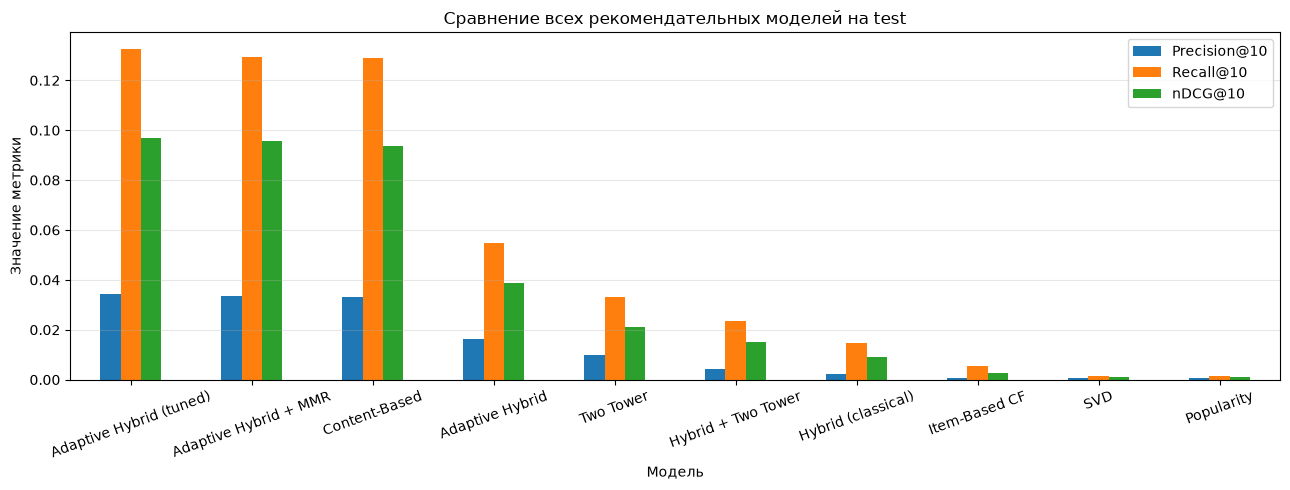

In [35]:
comparison_df.set_index("Model")[
    ["Precision@10", "Recall@10", "nDCG@10"]
].plot(
    kind="bar",
    figsize=(13, 5),
    rot=20,
)

plt.title("Сравнение всех рекомендательных моделей на test")
plt.xlabel("Модель")
plt.ylabel("Значение метрики")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Анализ качества по сегментам пользователей

Общая метрика может скрывать различия между пользователями с короткой и длинной историей.
Разделим пользователей по **числу оценок в train**, с теми же границами, что у адаптивного гибрида:

| Сегмент | Оценок в train | Интерпретация |
| --- | --- | --- |
| `new` | 0–4 | Короткая история или полностью неизвестный пользователь |
| `regular` | 5–49 | Средняя активность |
| `active` | 50 и более | Длинная история |

Здесь «новый» означает объём истории, а не дату регистрации: временных меток нет.
При текущем разбиении у каждого пользователя остаётся train-история, поэтому `new`
обычно содержит пользователей с небольшим числом оценок, а не настоящий cold start.
Отдельно покажем количество полностью неизвестных пользователей в test.

Используем `test_metrics_by_model` из итоговой оценки выше — повторное обучение и
повторная генерация рекомендаций не нужны. Метрики считаются только для пользователей
с хотя бы одной релевантной test-книгой (оценка ≥ 4), как и в общей test-таблице.


In [36]:
SEGMENT_ORDER = ["new", "regular", "active"]


def make_user_segments(train_df, relevant):
    """Сегмент зависит только от переданной обучающей истории."""
    # Границы совпадают с AdaptiveHybridRecommender.get_user_type.
    train_activity = train_df.groupby("user_id").size()
    all_user_ids = train_activity.index.union(pd.Index(list(relevant)))
    user_segments = pd.DataFrame({"user_id": all_user_ids})
    user_segments["train_ratings"] = (
        user_segments["user_id"].map(train_activity).fillna(0).astype(int)
    )
    user_segments["Segment"] = pd.cut(
        user_segments["train_ratings"], bins=[-1, 4, 49, np.inf], labels=SEGMENT_ORDER
    )
    user_segments["in_train"] = user_segments["train_ratings"] > 0
    user_segments["evaluated_on_test"] = user_segments["user_id"].isin(relevant)
    user_segments["cold_start_on_test"] = (
        user_segments["evaluated_on_test"] & ~user_segments["in_train"]
    )

    segment_population = user_segments.groupby("Segment", observed=False).agg(
        train_users=("in_train", "sum"),
        evaluated_test_users=("evaluated_on_test", "sum"),
        cold_start_test_users=("cold_start_on_test", "sum"),
    )
    segment_population["test_user_share"] = segment_population[
        "evaluated_test_users"
    ] / max(len(relevant), 1)
    return user_segments, segment_population


user_segments, segment_population = make_user_segments(train_df, test_relevant)
display(segment_population)


,train_users,evaluated_test_users,cold_start_test_users,test_user_share
Segment,,,,
new,23445,10274,0,0.278353
regular,28025,24692,0,0.668979
active,1954,1944,0,0.052669


### Метрики моделей внутри каждого сегмента

`users` — число оценённых пользователей, а не число оценок. Precision, Recall и nDCG
усредняются по пользователям. Все модели сравниваются на одной test-аудитории.
ILD доступен для двух адаптивных гибридов, для которых он сохраняется в test-оценке;
`NaN` в остальных строках означает, что разнообразие для этой модели не рассчитывалось.
Для пустой группы метрики также остаются `NaN`: отсутствие наблюдений не означает нулевое качество.


In [37]:
def summarize_segments(metrics_by_model, segments, k=10):
    """Усреднить уже рассчитанные per-user метрики, не вызывая модели повторно."""
    segment_map = segments.set_index("user_id")["Segment"]
    rows = []
    for model_name, metrics in metrics_by_model.items():
        metrics = metrics.copy()
        metrics["Segment"] = metrics["user_id"].map(segment_map)
        if metrics["Segment"].isna().any():
            raise ValueError("Не для всех пользователей определён сегмент")
        for segment in SEGMENT_ORDER:
            group = metrics[metrics["Segment"] == segment]
            rows.append(
                {
                    "Model": model_name,
                    "Segment": segment,
                    "users": len(group),
                    f"Precision@{k}": group["precision"].mean(),
                    f"Recall@{k}": group["recall"].mean(),
                    f"nDCG@{k}": group["ndcg"].mean(),
                    f"ILD@{k}": group["ild"].mean() if "ild" in group else np.nan,
                }
            )
    return pd.DataFrame(rows)


segment_report = summarize_segments(test_metrics_by_model, user_segments)
for segment in SEGMENT_ORDER:
    print("Сегмент:", segment)
    display(
        segment_report[segment_report["Segment"] == segment]
        .sort_values("nDCG@10", ascending=False, na_position="last")
        .reset_index(drop=True)
    )


Сегмент: new


,Model,Segment,users,Precision@10,Recall@10,nDCG@10,ILD@10
0,Adaptive Hybrid (tuned),new,10274,0.014872,0.148725,0.093620,0.739839
1,Adaptive Hybrid + MMR,new,10274,0.014074,0.140744,0.090150,0.818667
2,Content-Based,new,10274,0.014211,0.142106,0.089075,NaN
3,Hybrid + Two Tower,new,10274,0.004867,0.048667,0.029767,NaN
4,Hybrid (classical),new,10274,0.003747,0.037473,0.022403,NaN
5,Two Tower,new,10274,0.004195,0.041951,0.020735,NaN
6,Item-Based CF,new,10274,0.001625,0.016255,0.007361,NaN
7,Adaptive Hybrid,new,10274,0.000409,0.004088,0.001628,NaN
8,SVD,new,10274,0.000136,0.001363,0.000630,NaN
9,Popularity,new,10274,0.000078,0.000779,0.000317,NaN


Сегмент: regular


,Model,Segment,users,Precision@10,Recall@10,nDCG@10,ILD@10
0,Adaptive Hybrid (tuned),regular,24692,0.038579,0.131737,0.098797,0.663267
1,Adaptive Hybrid + MMR,regular,24692,0.038158,0.130295,0.098422,0.710683
2,Content-Based,regular,24692,0.037903,0.129471,0.096384,NaN
3,Adaptive Hybrid,regular,24692,0.023514,0.080020,0.056862,NaN
4,Two Tower,regular,24692,0.009412,0.029549,0.019181,NaN
5,Hybrid + Two Tower,regular,24692,0.003641,0.014377,0.009024,NaN
6,Hybrid (classical),regular,24692,0.001393,0.005863,0.003974,NaN
7,Popularity,regular,24692,0.000587,0.002084,0.001380,NaN
8,Item-Based CF,regular,24692,0.000373,0.001636,0.000961,NaN
9,SVD,regular,24692,0.000421,0.001466,0.000858,NaN


Сегмент: active


,Model,Segment,users,Precision@10,Recall@10,nDCG@10,ILD@10
0,Adaptive Hybrid (tuned),active,1944,0.082407,0.058630,0.092358,0.678298
1,Adaptive Hybrid + MMR,active,1944,0.077829,0.054573,0.088763,0.758468
2,Content-Based,active,1944,0.074177,0.053381,0.082384,NaN
3,Two Tower,active,1944,0.044084,0.028342,0.046570,NaN
4,Hybrid + Two Tower,active,1944,0.009877,0.007279,0.011575,NaN
5,Adaptive Hybrid,active,1944,0.006996,0.003886,0.008447,NaN
6,SVD,active,1944,0.006996,0.003537,0.007704,NaN
7,Hybrid (classical),active,1944,0.005401,0.003031,0.005724,NaN
8,Popularity,active,1944,0.000977,0.000657,0.001146,NaN
9,Item-Based CF,active,1944,0.000772,0.000311,0.000896,NaN


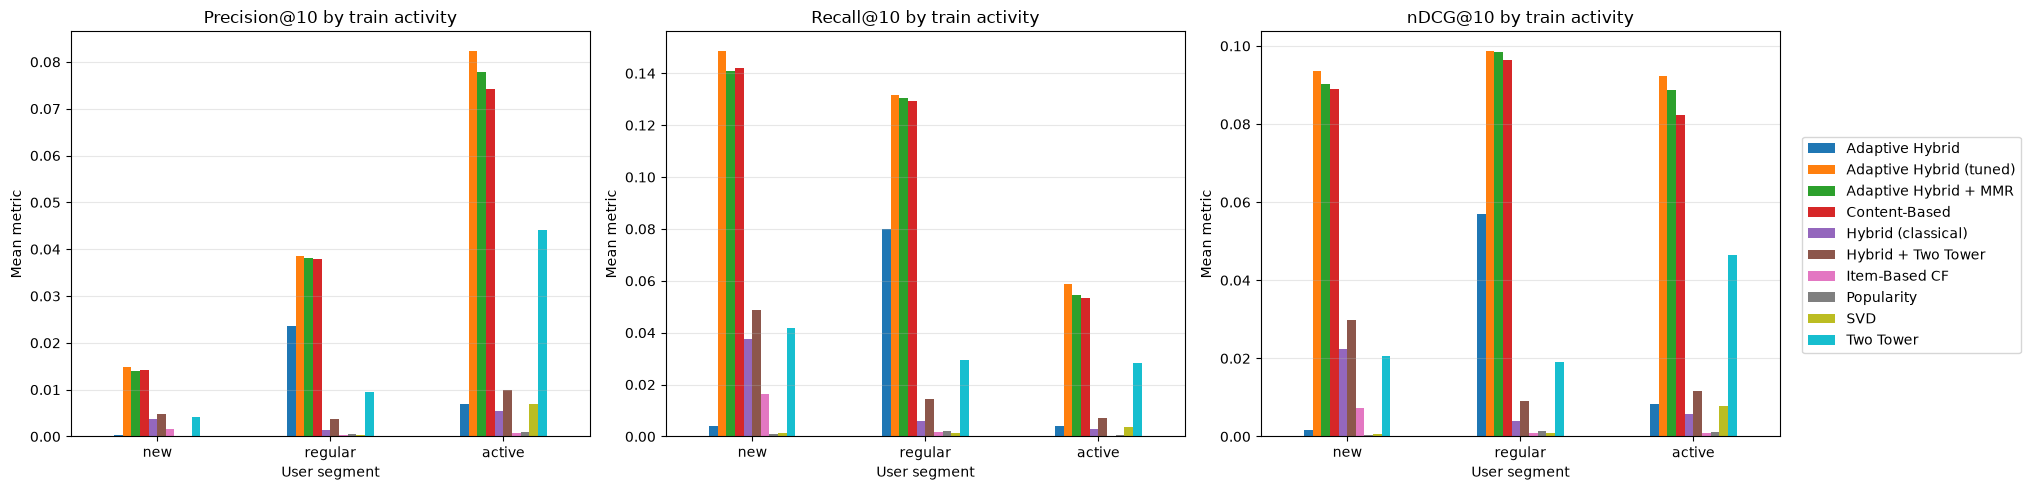

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ["Precision@10", "Recall@10", "nDCG@10"]):
    table = segment_report.pivot(index="Segment", columns="Model", values=metric)
    table.reindex(SEGMENT_ORDER).plot.bar(ax=ax, rot=0, legend=False)
    ax.set_title(metric + " by train activity")
    ax.set_xlabel("User segment")
    ax.set_ylabel("Mean metric")
    ax.grid(axis="y", alpha=0.3)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()
plt.show()


In [39]:
# Краткие выводы строятся по фактическим результатам, а не задаются заранее.
for segment in SEGMENT_ORDER:
    group = segment_report[
        (segment_report["Segment"] == segment) & (segment_report["users"] > 0)
    ]
    if group.empty:
        print(
            f"{segment}: нет test-пользователей с релевантными книгами; качество не оценено."
        )
        continue
    best_ndcg = group["nDCG@10"].max()
    best_models = group[np.isclose(group["nDCG@10"], best_ndcg)]["Model"].tolist()
    print(
        f"{segment}: пользователей {int(group['users'].iloc[0])}; "
        f"максимальный средний nDCG@10 = {best_ndcg:.4f}; модели: {', '.join(best_models)}."
    )

# Где адаптивный гибрид выигрывает или проигрывает контентной модели?
segment_ndcg = segment_report.pivot(index="Segment", columns="Model", values="nDCG@10")
if {"Content-Based", "Adaptive Hybrid (tuned)"}.issubset(segment_ndcg.columns):
    hybrid_by_segment = (
        segment_ndcg[["Content-Based", "Adaptive Hybrid (tuned)"]]
        .reindex(SEGMENT_ORDER)
        .copy()
    )
    hybrid_by_segment["delta_nDCG"] = (
        hybrid_by_segment["Adaptive Hybrid (tuned)"]
        - hybrid_by_segment["Content-Based"]
    )
    hybrid_by_segment["delta_percent"] = (
        100
        * hybrid_by_segment["delta_nDCG"]
        / hybrid_by_segment["Content-Based"].replace(0, np.nan)
    )
    display(hybrid_by_segment)


new: пользователей 10274; максимальный средний nDCG@10 = 0.0936; модели: Adaptive Hybrid (tuned).
regular: пользователей 24692; максимальный средний nDCG@10 = 0.0988; модели: Adaptive Hybrid (tuned).
active: пользователей 1944; максимальный средний nDCG@10 = 0.0924; модели: Adaptive Hybrid (tuned).


Model,Content-Based,Adaptive Hybrid (tuned),delta_nDCG,delta_percent
Segment,,,,
new,0.089075,0.093620,0.004545,5.102581
regular,0.096384,0.098797,0.002413,2.503732
active,0.082384,0.092358,0.009974,12.106695


### Как интерпретировать результаты по сегментам

- Сравниваем модели **внутри одного сегмента**: длинная история меняет сложность задачи
  и количество релевантных книг, поэтому абсолютные метрики разных групп неравнозначны.
- Проверяем, помогает ли адаптивный гибрид пользователям с короткой историей и сохраняет
  ли качество на активных; таблица `delta_nDCG` показывает отличие от Content-Based.
- Для MMR сопоставляем nDCG и ILD внутри группы: более разнообразная выдача может стоить
  части релевантности. Средняя приемлемая потеря на validation не гарантирует её соблюдения
  в каждом test-сегменте.
- Учитываем численность групп: результат малочисленного сегмента менее устойчив.
  Максимальное среднее здесь не является доказательством статистически значимого превосходства.
- Test используется для итогового анализа. Границы сегментов, веса гибрида и параметр MMR
  не подбираем по этим результатам; новые гипотезы проверяем на validation.


### Сквозной пайплайн: от CSV до выдачи и отчёта

`run_pipeline` повторяет все этапы на переданной папке с CSV той же схемы:
**загрузка → очистка и split → признаки → классические модели и Two Tower →
подбор весов и MMR на validation → выдача → test-метрики и отчёт по сегментам**.

Функция создаёт собственные модели и признаки, а не использует ранее обученные глобальные
экземпляры. Поэтому последовательные запуски на разных данных не смешивают историю.
Вариант `use_neural=False` запускает ту же цепочку без Two Tower для сравнения.
В режиме с нейросетью она участвует и в пуле кандидатов, и в весах, и в Optuna.
`Hybrid (classical)` остаётся контрольным вариантом без нейросети.

CSV читаются из `data_dir`; для скачивания Goodbooks можно явно задать `download=True`.
Требуются `books.csv`, `ratings.csv`, `book_tags.csv`, `tags.csv`, `to_read.csv`.
`max_users` ограничивает весь эксперимент, `tuning_users` — validation для подбора,
`eval_users` — test-отчёт. `None` означает всех пользователей. В config.json сохраняются
фактические размеры выборок: отчёт на подвыборке нельзя выдавать за результат на всей базе.

В `output_dir/processed/` сохраняются разбиения, в `output_dir/reports/` — отчёт Markdown,
CSV с общими и сегментными метриками, примерами рекомендаций, историей обучения,
результатами подбора и выбранными весами, а также графики и параметры запуска.
Повторный запуск в той же папке обновляет результаты. Обученная модель возвращается
в памяти: `result["model"].recommend(user_id, N=10)`.


In [40]:
import json
from time import perf_counter


def _sample_relevant(relevant, max_users, random_state):
    if max_users is None or len(relevant) <= max_users:
        return dict(relevant)
    users = np.random.default_rng(random_state).choice(
        sorted(relevant), max_users, replace=False
    )
    return {int(u): relevant[u] for u in users}


def evaluate_pipeline_models(recommenders, relevant, content_model, k):
    """Один вызов модели на пользователя: качество и ILD считаются на одной выдаче."""
    per_user, summary = {}, []
    for name, recommend in recommenders.items():
        rows = []
        for user_id, actual in relevant.items():
            recs = recommend(user_id, N=k)
            predicted = [rec["book_id"] for rec in recs]
            rows.append(
                {
                    "user_id": user_id,
                    "precision": precision_at_k(actual, predicted, k),
                    "recall": recall_at_k(actual, predicted, k),
                    "ndcg": ndcg_at_k(actual, predicted, k),
                    "ild": intra_list_diversity(recs, content_model),
                }
            )
        frame = pd.DataFrame(rows)
        per_user[name] = frame
        summary.append(
            {
                "Model": name,
                "users": len(frame),
                f"Precision@{k}": frame["precision"].mean(),
                f"Recall@{k}": frame["recall"].mean(),
                f"nDCG@{k}": frame["ndcg"].mean(),
                f"ILD@{k}": frame["ild"].mean(),
            }
        )
    return pd.DataFrame(summary).sort_values(f"nDCG@{k}", ascending=False), per_user


def run_pipeline(
    data_dir=PROJECT_ROOT / "data" / "raw",
    output_dir=PROJECT_ROOT / "artifacts" / "notebook_pipeline",
    download=False,
    max_users=None,
    use_neural=True,
    epochs=5,
    batch_size=1024,
    svd_epochs=50,
    n_trials=30,
    tuning_users=200,
    eval_users=None,
    k=10,
    candidates_k=100,
    recommend_user_ids=None,
    random_state=42,
    device=None,
):
    """CSV → split → признаки → обучение → подбор на val → выдача → test-отчёт.

    Все модели создаются заново и используют локальные данные этого запуска.
    Результат содержит готовую модель и таблицы; повторное обучение для выдачи не нужно.
    """
    if k < 1 or candidates_k < k or n_trials < 0 or svd_epochs < 1:
        raise ValueError(
            "Нужны k >= 1, candidates_k >= k, svd_epochs >= 1, n_trials >= 0"
        )
    if use_neural and (epochs < 1 or batch_size < 1):
        raise ValueError("Для Two Tower нужны положительные epochs и batch_size")
    for limit in [max_users, tuning_users, eval_users]:
        if limit is not None and limit < 1:
            raise ValueError(
                "Ограничение пользователей должно быть положительным или None"
            )
    started = perf_counter()
    data_dir, output_dir = Path(data_dir), Path(output_dir)
    if download:
        # Скачивание включается явно; готовые локальные CSV скачивать заново не нужно.
        from src.data.make_dataset import load_kaggle_dataset

        load_kaggle_dataset(path=data_dir)

    print("1/6 Загрузка и подготовка данных", flush=True)
    data = laod_dataframes(data_dir)
    books, book_tags, tags = data["df_books"], data["df_book_tags"], data["df_tags"]
    cleaned = clean_ratings(data["df_ratings"], books)
    if max_users is not None and cleaned["user_id"].nunique() > max_users:
        chosen = np.random.default_rng(random_state).choice(
            np.sort(cleaned["user_id"].unique()), max_users, replace=False
        )
        cleaned = cleaned[cleaned["user_id"].isin(chosen)].reset_index(drop=True)
    train, validation, test = train_test_val_per_user(
        cleaned, random_state=random_state
    )

    def relevant_from(frame):
        return (
            frame[frame["rating"] >= 4].groupby("user_id")["book_id"].agg(set).to_dict()
        )

    val_relevant_local, test_relevant_local = (
        relevant_from(validation),
        relevant_from(test),
    )
    if not val_relevant_local or not test_relevant_local:
        raise ValueError(
            "Нужны релевантные книги в val и test; увеличьте выборку пользователей"
        )
    tuning_relevant = _sample_relevant(val_relevant_local, tuning_users, random_state)
    evaluation_relevant = _sample_relevant(
        test_relevant_local, eval_users, random_state
    )
    builder, user_table, book_table = build_feature_tables(
        train, books, book_tags, tags
    )
    train_table = builder.transform(train, leave_one_out=True)

    print("2/6 Обучение классических моделей и Two Tower", flush=True)
    base = {}
    training_times = []
    factories = {
        "pop": lambda: recommend_popular_recomemder(train),
        "content": lambda: content_based_recomender(train, book_tags, books, tags),
        "item": lambda: cb_item_recomennder(train, books),
        "svd": lambda: svd_recommender(
            train, books, n_epochs=svd_epochs, random_state=random_state
        ),
    }
    for name, factory in factories.items():
        timer = perf_counter()
        base[name] = factory()
        training_times.append({"model": name, "seconds": perf_counter() - timer})
    if use_neural:
        timer = perf_counter()
        base["two_tower"] = TwoTowerRecommender(
            train,
            books,
            train_features=train_table,
            user_features=user_table,
            book_features=book_table,
            random_state=random_state,
            device=device,
        ).fit(tuning_relevant, epochs=epochs, batch_size=batch_size, k=k)
        training_times.append({"model": "two_tower", "seconds": perf_counter() - timer})

    print("3/6 Подбор весов гибрида и MMR только на validation", flush=True)
    classical = HybridRecommender(
        train,
        models={name: model for name, model in base.items() if name != "two_tower"},
    )
    hybrid = HybridRecommender(train, models=base)
    initial_adaptive = AdaptiveHybridRecommender(train, models=base)
    adaptive = AdaptiveHybridRecommender(train, models=base)
    search = pd.DataFrame(columns=["user_type", "trial", *base, f"nDCG@{k}"])
    if n_trials:
        adaptive.adaptive_weights, search = optimize_adaptive_weights(
            adaptive,
            tuning_relevant,
            n_trials=n_trials,
            k=k,
            candidates_k=candidates_k,
            random_state=random_state,
        )
    mmr_weight, mmr_table, _ = tune_mmr(
        adaptive,
        base["content"],
        tuning_relevant,
        k=k,
        candidates_k=candidates_k,
        max_users=None,
        random_state=random_state,
    )
    final_model = BalancedRecommender(
        adaptive, base["content"], mmr_weight, candidates_k
    )

    print("4/6 Генерация итоговых рекомендаций", flush=True)
    if recommend_user_ids is None:
        recommend_user_ids = sorted(evaluation_relevant)[:5]
    recommendation_rows = []
    for user_id in recommend_user_ids:
        for rank, rec in enumerate(final_model.recommend(user_id, N=k), start=1):
            recommendation_rows.append({"user_id": user_id, "rank": rank, **rec})
    recommendations = pd.DataFrame(
        recommendation_rows,
        columns=["user_id", "rank", "book_id", "score", "mmr_score"],
    )
    recommendations = recommendations.merge(
        books[["id", "title", "authors"]].rename(columns={"id": "book_id"}),
        on="book_id",
        how="left",
        validate="many_to_one",
    )

    print("5/6 Итоговая оценка на test и анализ сегментов", flush=True)
    labels = {
        "pop": "Popularity",
        "content": "Content-Based",
        "item": "Item-Based CF",
        "svd": "SVD",
        "two_tower": "Two Tower",
    }
    recommenders = {labels[name]: model.recommend for name, model in base.items()}
    recommenders["Hybrid (classical)"] = classical.recommend
    if use_neural:
        recommenders["Hybrid + Two Tower"] = hybrid.recommend
    recommenders["Adaptive Hybrid"] = initial_adaptive.recommend
    recommenders["Adaptive Hybrid (tuned)"] = adaptive.recommend
    recommenders["Adaptive Hybrid + MMR"] = final_model.recommend
    metrics, user_metrics = evaluate_pipeline_models(
        recommenders, evaluation_relevant, base["content"], k
    )
    segments, population = make_user_segments(train, evaluation_relevant)
    segment_metrics = summarize_segments(user_metrics, segments, k=k)

    print("6/6 Сохранение результатов и отчёта", flush=True)
    processed_dir, report_dir = output_dir / "processed", output_dir / "reports"
    processed_dir.mkdir(parents=True, exist_ok=True)
    report_dir.mkdir(parents=True, exist_ok=True)
    for name, frame in [("train", train), ("val", validation), ("test", test)]:
        frame.to_csv(processed_dir / f"{name}.csv", index=False)
    metrics.to_csv(report_dir / "metrics.csv", index=False)
    segment_metrics.to_csv(report_dir / "segments.csv", index=False)
    population.to_csv(report_dir / "segment_population.csv")
    recommendations.to_csv(report_dir / "recommendations.csv", index=False)
    mmr_table.to_csv(report_dir / "mmr_validation.csv", index=False)
    search.to_csv(report_dir / "weight_search.csv", index=False)
    pd.DataFrame(training_times).to_csv(report_dir / "training_times.csv", index=False)
    for name, frame in user_metrics.items():
        frame.to_csv(report_dir / f"users_{name.replace(' ', '_')}.csv", index=False)
    if use_neural:
        base["two_tower"].history.to_csv(
            report_dir / "two_tower_history.csv", index=False
        )
    config = {
        "data_dir": str(data_dir.resolve()),
        "random_state": random_state,
        "max_users": max_users,
        "use_neural": use_neural,
        "epochs": epochs,
        "batch_size": batch_size,
        "svd_epochs": svd_epochs,
        "n_trials": n_trials,
        "k": k,
        "candidates_k": candidates_k,
        "tuning_users_limit": tuning_users,
        "tuning_users": len(tuning_relevant),
        "eval_users_limit": eval_users,
        "evaluated_test_users": len(evaluation_relevant),
        "all_eligible_test_users": len(test_relevant_local),
        "train_rows": len(train),
        "val_rows": len(validation),
        "test_rows": len(test),
        "model_names": list(base),
        "mmr_weight": mmr_weight,
        "duration_seconds": perf_counter() - started,
    }
    (report_dir / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    (report_dir / "adaptive_weights.json").write_text(
        json.dumps(adaptive.adaptive_weights, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    ax = metrics.set_index("Model")[
        [f"Precision@{k}", f"Recall@{k}", f"nDCG@{k}"]
    ].plot.bar(figsize=(13, 5), rot=25)
    ax.set_title("Test metrics")
    ax.figure.tight_layout()
    ax.figure.savefig(report_dir / "metrics.png", dpi=150)
    plt.close(ax.figure)
    ax = (
        segment_metrics.pivot(index="Segment", columns="Model", values=f"nDCG@{k}")
        .reindex(SEGMENT_ORDER)
        .plot.bar(figsize=(13, 5), rot=0)
    )
    ax.set_title("Test nDCG by train activity")
    ax.figure.tight_layout()
    ax.figure.savefig(report_dir / "segments.png", dpi=150)
    plt.close(ax.figure)
    report_path = report_dir / "report.md"
    report_path.write_text(
        "\n".join(
            [
                "# Сквозной запуск рекомендательной системы",
                "",
                f"Источник: `{data_dir.resolve()}`; seed={random_state}; K={k}.",
                "",
                f"Test-пользователей: {len(evaluation_relevant)} из {len(test_relevant_local)} с релевантными книгами.",
                "Веса моделей, баланс MMR и лучшая эпоха выбраны только по validation.",
                f"Модели: {', '.join(base)}. Вес релевантности MMR: {mmr_weight}.",
                "",
                "## Сравнение на test",
                "",
                "```text",
                metrics.to_string(index=False),
                "```",
                "",
                "![Метрики](metrics.png)",
                "",
                "## Сегменты",
                "",
                "```text",
                population.to_string(),
                "```",
                "",
                "```text",
                segment_metrics.to_string(index=False),
                "```",
                "",
                "![Сегменты](segments.png)",
                "",
                "## Примеры рекомендаций",
                "",
                "```text",
                recommendations.head(30).to_string(index=False),
                "```",
                "",
                "Метрики — средние по пользователям. Сегменты определены числом train-оценок.",
                "Сравните Hybrid (classical) и Hybrid + Two Tower, затем адаптивный гибрид и MMR.",
                "Превосходство одной модели не предполагается заранее; результаты требуют интерпретации.",
                "Полные параметры и размеры выборок сохранены в config.json.",
            ]
        ),
        encoding="utf-8",
    )
    print("Отчёт:", report_path)
    return {
        "model": final_model,
        "base_models": base,
        "hybrid": hybrid,
        "adaptive": adaptive,
        "features": builder,
        "metrics": metrics,
        "segments": segment_metrics,
        "recommendations": recommendations,
        "report_path": report_path,
        "config": config,
    }


In [41]:
# Выполните ячейки с определениями классов и функций выше, затем включите запуск.
# Здесь ограничиваем число пользователей для первого эксперимента.
# Для полной базы задайте max_users=None и eval_users=None; для подбора на всей val — tuning_users=None.
RUN_PIPELINE = False
if RUN_PIPELINE:
    pipeline_result = run_pipeline(
        data_dir=PROJECT_ROOT / "data" / "raw",
        output_dir=PROJECT_ROOT / "artifacts" / "notebook_pipeline",
        max_users=200, epochs=2, n_trials=5, tuning_users=100,
        random_state=RANDOM_STATE,
    )
    display(pipeline_result["metrics"])
    display(pipeline_result["recommendations"].head(10))
    print(pipeline_result["report_path"])
